## Customer Behavior Modeling and Offer Policy Design

The goal of the project is to find out which offers give the best result for different types of customers.

The resulting policy should increase total reward and reduce the churn rate.

Import the required libraries

In [ ]:
import zipfile
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import importlib.util
import pandas as pd
import random
from sklearn.model_selection import train_test_split, KFold, ParameterGrid

In [ ]:
with zipfile.ZipFile("data_scientist_assignment.zip", 'r') as zipfile:
  zipfile.extractall()

In [ ]:
df=pd.read_csv("ds_assignment_customer_data.csv", delimiter=',')

Let's see what the data looks like

In [ ]:
df.head()

,customer_id,balance,avg_spending,salary,savings_rate,responsiveness
0,0,9633.92,1190.87,2253,0.056,0.82
1,1,6626.33,3516.68,5933,0.030,0.54
2,2,7107.98,1768.14,3784,0.042,0.98
3,3,14269.44,2087.64,5126,0.045,0.83
4,4,9766.83,4691.56,6261,0.027,0.66


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   customer_id     500 non-null    int64  
 1   balance         500 non-null    float64
 2   avg_spending    500 non-null    float64
 3   salary          500 non-null    int64  
 4   savings_rate    500 non-null    float64
 5   responsiveness  500 non-null    float64
dtypes: float64(4), int64(2)
memory usage: 23.6 KB


In [ ]:
df.duplicated().sum()

np.int64(0)

The data has neither missing values nor duplicates

In [ ]:
df.drop('customer_id', axis=1).describe()

,balance,avg_spending,salary,savings_rate,responsiveness
count,500.000000,500.000000,500.000000,500.000000,500.000000
mean,9494.807540,3490.680940,5165.408000,0.030012,0.580320
std,3493.690561,1448.972868,1690.957351,0.014024,0.251576
min,3032.400000,895.590000,2004.000000,0.010000,0.100000
25%,6695.722500,2372.907500,3723.750000,0.018000,0.427500
50%,9231.400000,3356.450000,5359.000000,0.028000,0.645000
75%,11523.707500,4422.567500,6575.750000,0.041000,0.760000
max,19726.090000,8472.760000,7998.000000,0.060000,1.000000


Check whether the data contains outliers

In [ ]:
def outlier_percentage(df):
    numeric_cols = df.drop('customer_id', axis=1)
    outlier_stats = {}

    for col in numeric_cols:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1

        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
        outlier_percent = (len(outliers) / len(df)) * 100

        outlier_stats[col] = outlier_percent

    return pd.DataFrame(outlier_stats.items(), columns=['Column', 'Outlier_Percentage(%)'])

outlier_percentages = outlier_percentage(df)
outlier_percentages

,Column,Outlier_Percentage(%)
0,balance,1.2
1,avg_spending,0.8
2,salary,0.0
3,savings_rate,0.0
4,responsiveness,0.0


The balance and spending fields have a small number of outliers. It is interesting to see whether the customers with 'outlier' values in these two fields are the same ones

In [ ]:
Q1_balance = df['balance'].quantile(0.25)
Q3_balance = df['balance'].quantile(0.75)
IQR_balance = Q3_balance - Q1_balance
lower_bound_balance = Q1_balance - 1.5 * IQR_balance
upper_bound_balance = Q3_balance + 1.5 * IQR_balance
balance_outliers_df = df[(df['balance'] < lower_bound_balance) | (df['balance'] > upper_bound_balance)]
print("Balance Outliers:")
print(balance_outliers_df)

Q1_spending = df['avg_spending'].quantile(0.25)
Q3_spending = df['avg_spending'].quantile(0.75)
IQR_spending = Q3_spending - Q1_spending
lower_bound_spending = Q1_spending - 1.5 * IQR_spending
upper_bound_spending = Q3_spending + 1.5 * IQR_spending
spending_outliers_df = df[(df['avg_spending'] < lower_bound_spending) | (df['avg_spending'] > upper_bound_spending)]
print("\nAvg Spending Outliers:")
print(spending_outliers_df)

Balance Outliers:
     customer_id   balance  avg_spending  salary  savings_rate  responsiveness
9              9  18943.93       4322.51    4040         0.018            0.68
74            74  19557.66       3977.65    4690         0.014            0.66
93            93  18902.98       4172.70    4296         0.017            0.67
238          238  18853.70       3825.32    4687         0.022            0.40
249          249  19726.09       5491.76    5768         0.019            0.66
453          453  19693.21       3795.36    4551         0.028            0.62

Avg Spending Outliers:
     customer_id   balance  avg_spending  salary  savings_rate  responsiveness
115          115  16158.59       7965.98    7324         0.024            0.59
204          204  11646.26       7873.78    7929         0.021            0.47
383          383  12658.45       8472.76    7970         0.021            0.45
487          487  13811.19       8028.30    7445         0.017            0.58


Look at the distribution of the variables

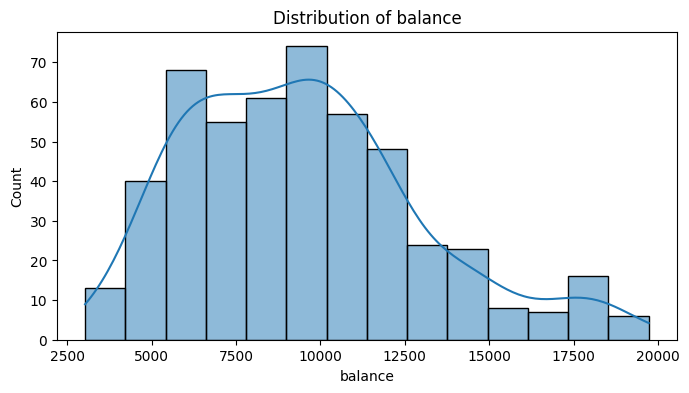

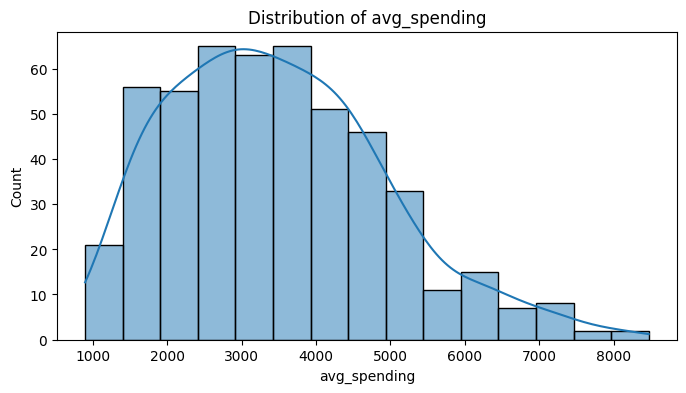

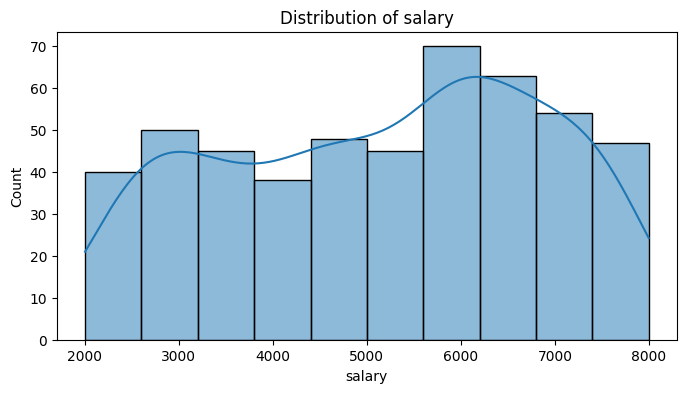

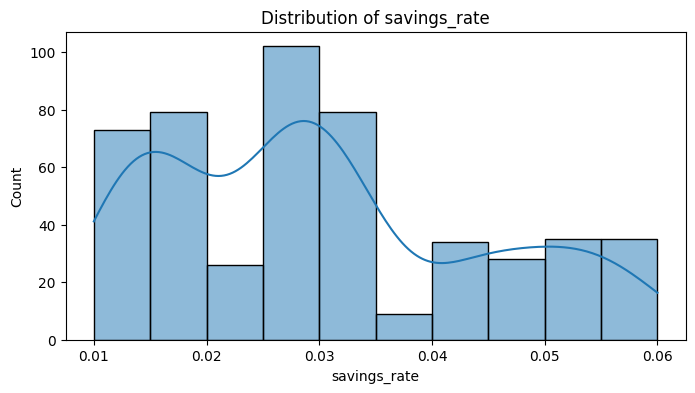

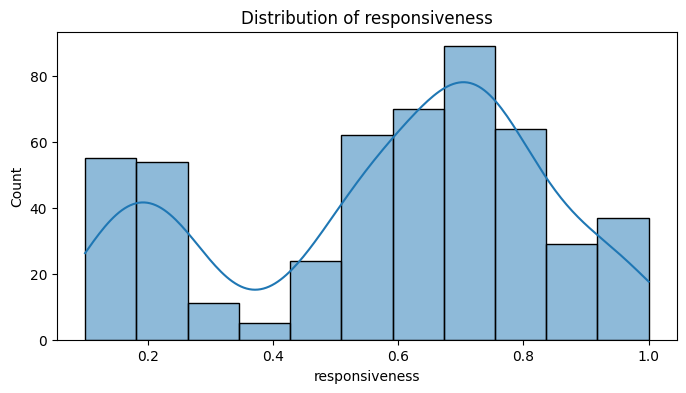

In [ ]:
features = [col for col in df.columns if col != 'customer_id']
for col in features:
    plt.figure(figsize=(8, 4))
    sns.histplot(df[col], kde=True)
    plt.title(f'Distribution of {col}')
    plt.show()

The current balance and average spending fields are close to a normal distribution

The savings rate is low for most customers (skewed right), while the responsiveness to offers is high for most customers (skewed left)

Measure the correlation between the variables

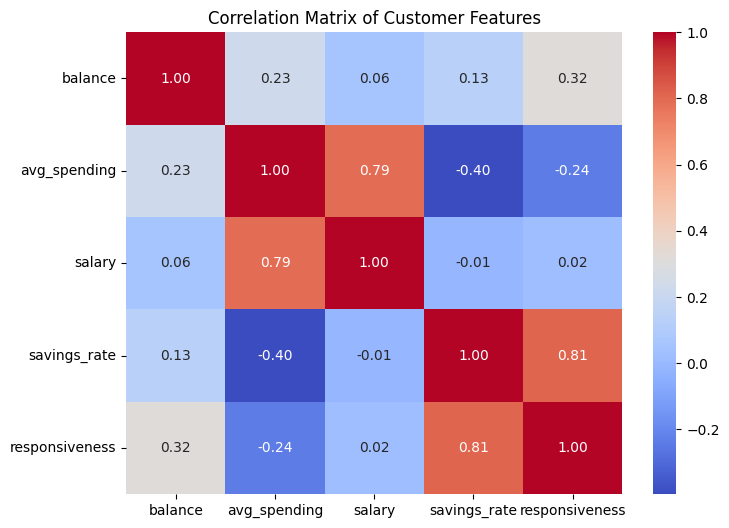

In [ ]:
correlation_matrix = df[features].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix of Customer Features')
plt.show()

The correlation matrix shows a strong linear relationship between salary and average monthly spending, which makes sense: high income customers also spend more. There is a strong linear relationship between savings and responsiveness to offers, so customers who save often use various financial offers. It may be that the financial offers customers take part in involve saving, and this is what drives the strong relationship between these variables. In any case, this is an important signal that customers who often respond to offers should get an offer related to savings. There is a negative relationship between average monthly spending and savings, which is also logical: if you spend a lot, less is left to save. This analysis will help us try to build a recommendation policy based on expert and statistical analysis.

Based on this analysis we can try the following policy, which does not depend on any ML algorithm and simply follows from the analysis of the variables and expert judgment:

1) Customers with high 'responsiveness' and high 'savings_rate' get cashback on the savings they make.

2) Customers with high 'responsiveness' and low 'savings_rate' get an automatic savings offer.

Before building this kind of rule-based policy, I want to try segmenting the customers with clustering, which may bring out the groups mentioned above.

In [ ]:
X = df[features].values
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

wcss = []
silhouette_scores = []
max_clusters = 20

for i in range(2, max_clusters + 1):
    kmeans = KMeans(n_clusters=i, init='k-means++', max_iter=300, n_init=10, random_state=42)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

    silhouette_avg = silhouette_score(X_scaled, kmeans.labels_)
    silhouette_scores.append(silhouette_avg)

    print(f"Clusters: {i}, WCSS: {kmeans.inertia_:.2f}, Silhouette Score: {silhouette_avg:.4f}")

Clusters: 2, WCSS: 1751.18, Silhouette Score: 0.2696
Clusters: 3, WCSS: 1308.46, Silhouette Score: 0.2990
Clusters: 4, WCSS: 1047.77, Silhouette Score: 0.3096
Clusters: 5, WCSS: 883.76, Silhouette Score: 0.3140
Clusters: 6, WCSS: 740.83, Silhouette Score: 0.3209
Clusters: 7, WCSS: 630.76, Silhouette Score: 0.3335
Clusters: 8, WCSS: 553.74, Silhouette Score: 0.3434
Clusters: 9, WCSS: 515.48, Silhouette Score: 0.3409
Clusters: 10, WCSS: 478.87, Silhouette Score: 0.3152
Clusters: 11, WCSS: 455.59, Silhouette Score: 0.2887
Clusters: 12, WCSS: 427.29, Silhouette Score: 0.3082
Clusters: 13, WCSS: 409.68, Silhouette Score: 0.2788
Clusters: 14, WCSS: 383.11, Silhouette Score: 0.2827
Clusters: 15, WCSS: 363.04, Silhouette Score: 0.2778
Clusters: 16, WCSS: 344.44, Silhouette Score: 0.2744
Clusters: 17, WCSS: 331.49, Silhouette Score: 0.2708
Clusters: 18, WCSS: 317.54, Silhouette Score: 0.2712
Clusters: 19, WCSS: 305.89, Silhouette Score: 0.2698
Clusters: 20, WCSS: 295.29, Silhouette Score: 0.268

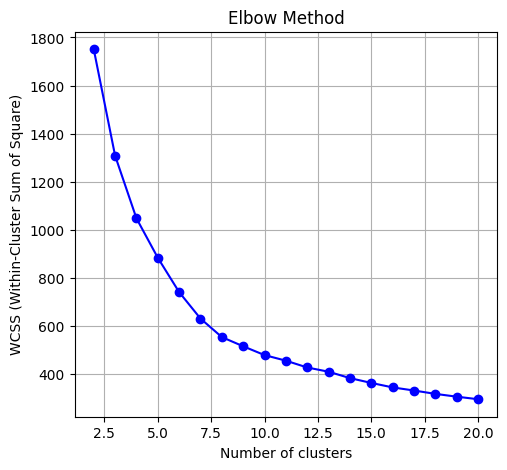

In [ ]:
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(range(2, max_clusters + 1), wcss, marker='o', linestyle='-', color='b')
plt.title('Elbow Method')
plt.xlabel('Number of clusters')
plt.ylabel('WCSS (Within-Cluster Sum of Square)')
plt.grid(True)

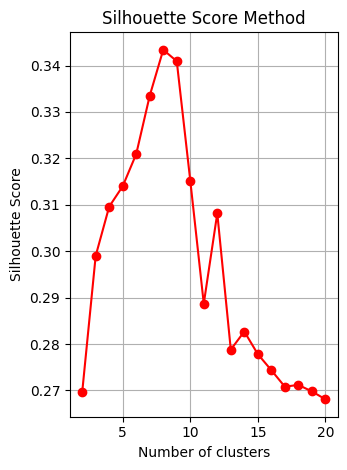

In [ ]:
plt.subplot(1, 2, 2)
plt.plot(range(2, max_clusters + 1), silhouette_scores, marker='o', linestyle='-', color='r')
plt.title('Silhouette Score Method')
plt.xlabel('Number of clusters')
plt.ylabel('Silhouette Score')
plt.grid(True)
plt.tight_layout()
plt.show()

To find the optimal number of clusters I use the elbow method and the silhouette score. The silhouette score reaches its maximum when the number of clusters is eight. With the elbow method the turning point of the function is also around eight, so I will use eight as the optimal number of clusters and see how homogeneous the segments are and what results we get in the simulation.

Using 8 clusters as specified


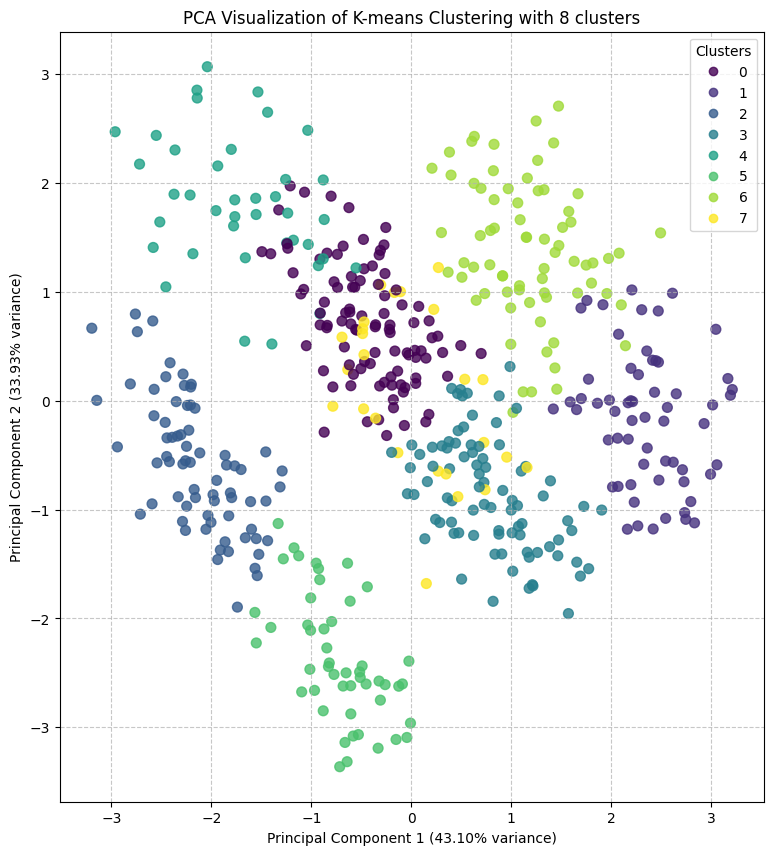

In [ ]:
n_clusters = 8
print(f"Using {n_clusters} clusters as specified")

kmeans_model = KMeans(n_clusters=n_clusters, init='k-means++',
                    max_iter=300, n_init=10, random_state=42)
kmeans_model.fit(X_scaled)

df_with_clusters_8 = df.copy()
df_with_clusters_8['Cluster'] = kmeans_model.labels_

plt.figure(figsize=(20, 10))
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.subplot(1, 2, 1)
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans_model.labels_, cmap='viridis', s=50, alpha=0.8)
plt.title(f'PCA Visualization of K-means Clustering with {n_clusters} clusters')
plt.xlabel(f'Principal Component 1 ({pca.explained_variance_ratio_[0]:.2%} variance)')
plt.ylabel(f'Principal Component 2 ({pca.explained_variance_ratio_[1]:.2%} variance)')
plt.legend(*scatter.legend_elements(), title="Clusters")
plt.grid(True, linestyle='--', alpha=0.7)

Computing t-SNE embedding (this may take a moment)...


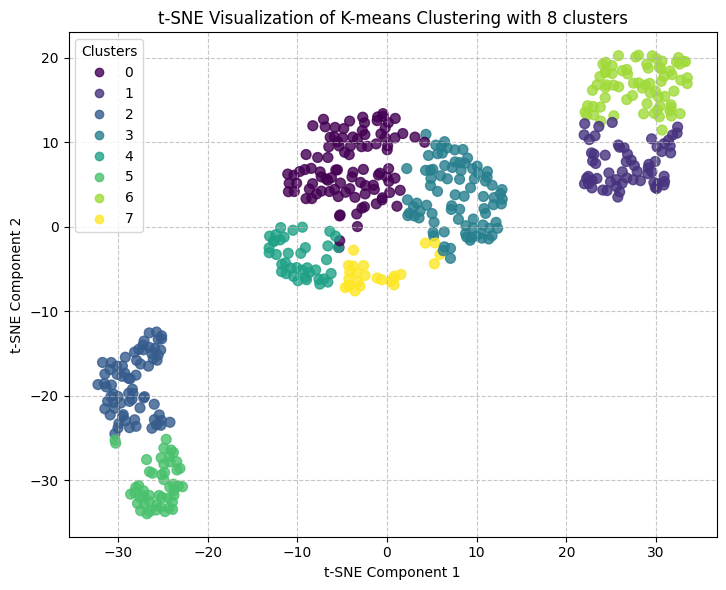

In [ ]:
print("Computing t-SNE embedding (this may take a moment)...")
tsne = TSNE(n_components=2, perplexity=30, n_iter=1000, random_state=42)
X_tsne = tsne.fit_transform(X_scaled)
plt.figure(figsize=(14, 6))
plt.subplot(1, 2, 2)
scatter = plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=kmeans_model.labels_, cmap='viridis', s=50, alpha=0.8)
plt.title(f't-SNE Visualization of K-means Clustering with {n_clusters} clusters')
plt.xlabel('t-SNE Component 1')
plt.ylabel('t-SNE Component 2')
plt.legend(*scatter.legend_elements(), title="Clusters")
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

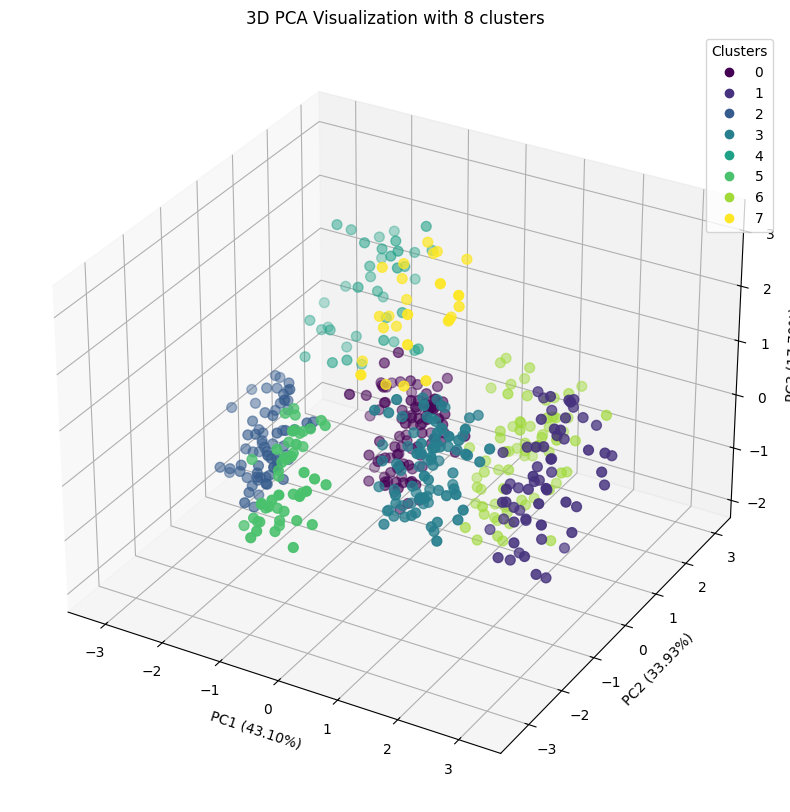

In [ ]:
pca_3d = PCA(n_components=3)
X_pca_3d = pca_3d.fit_transform(X_scaled)

fig = plt.figure(figsize=(12, 10))
ax = fig.add_subplot(111, projection='3d')

scatter = ax.scatter(
    X_pca_3d[:, 0],
    X_pca_3d[:, 1],
    X_pca_3d[:, 2],
    c=kmeans_model.labels_,
    cmap='viridis',
    s=50
)

ax.set_xlabel(f'PC1 ({pca_3d.explained_variance_ratio_[0]:.2%})')
ax.set_ylabel(f'PC2 ({pca_3d.explained_variance_ratio_[1]:.2%})')
ax.set_zlabel(f'PC3 ({pca_3d.explained_variance_ratio_[2]:.2%})')
plt.title(f'3D PCA Visualization with {n_clusters} clusters')
plt.legend(*scatter.legend_elements(), title="Clusters")
plt.show()

In [ ]:
cluster_counts = df_with_clusters_8['Cluster'].value_counts().sort_index()
print("\nCluster Distribution:")
for cluster, count in cluster_counts.items():
    print(f"Cluster {cluster}: {count} samples ({count/len(df_with_clusters_8)*100:.2f}%)")

print("\nCluster Statistics (means of each feature per cluster):")
cluster_means = df_with_clusters_8.groupby('Cluster')[features].mean()
print(cluster_means)


Cluster Distribution:
Cluster 0: 99 samples (19.80%)
Cluster 1: 61 samples (12.20%)
Cluster 2: 71 samples (14.20%)
Cluster 3: 85 samples (17.00%)
Cluster 4: 39 samples (7.80%)
Cluster 5: 49 samples (9.80%)
Cluster 6: 71 samples (14.20%)
Cluster 7: 25 samples (5.00%)

Cluster Statistics (means of each feature per cluster):
              balance  avg_spending       salary  savings_rate  responsiveness
Cluster                                                                       
0         8980.924040   4264.825354  6436.929293      0.029576        0.652626
1        10150.538361   1697.341311  3466.655738      0.050000        0.837541
2         6750.652676   4636.907606  6341.887324      0.014690        0.201972
3         8577.477765   2436.291765  3635.941176      0.029235        0.646941
4        14937.971538   6376.826667  6645.948718      0.019359        0.558462
5         6580.227143   2363.202857  3294.816327      0.014531        0.180408
6        10166.624789   3286.392817  6504.9

After k-means clustering we have eight clusters, and each cluster holds at least 5% of the data, which means these groups can be evaluated statistically :))

Let's go through the typical behavior of each cluster:

1) Cluster 0 has customers with higher spending, a relatively low savings share and high responsiveness, so the optimal offer for them could be auto_save_offer.

2) Cluster 1 has customers with high savings and high responsiveness, who can be offered cashback.

3) Cluster 2 has customers with low savings and low responsiveness, to whom we can make no offer.

4) Cluster 3 is roughly similar to cluster 0, so we offer auto_save_offer.

5) Cluster 4 is a group of customers with low savings and relatively high responsiveness, to whom we can send a reminder.

6) Cluster 5 is similar to cluster 2, so none.

7) Cluster 6: cashback.

8) Cluster 7: reminder.

The visualizations suggest that three clusters stand out, so we can also look at the outputs for three clusters

Using 3 clusters as specified


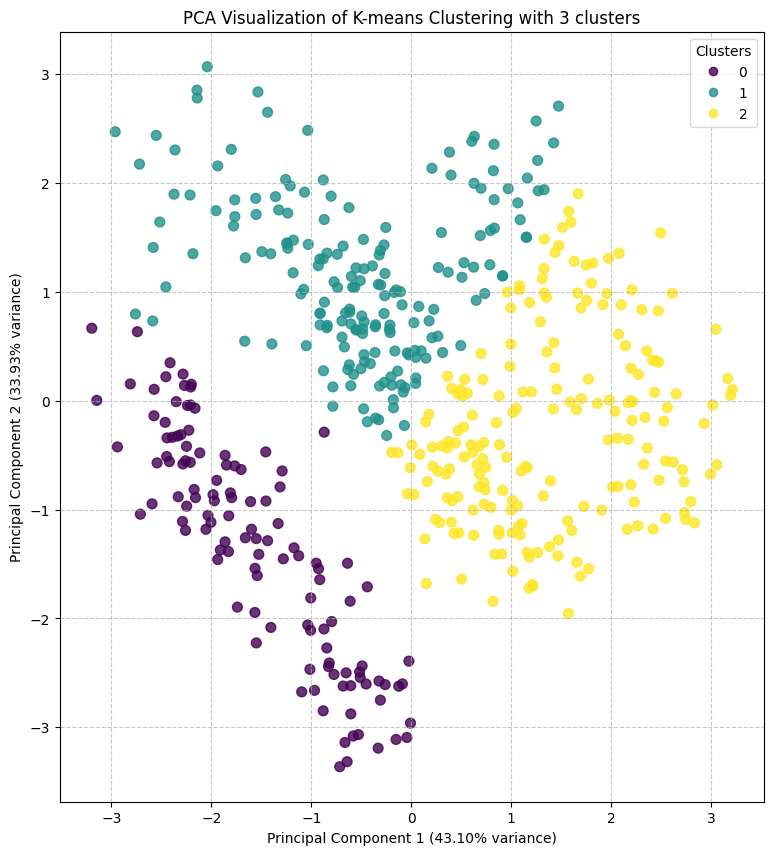

In [ ]:
n_clusters = 3
print(f"Using {n_clusters} clusters as specified")

kmeans_model = KMeans(n_clusters=n_clusters, init='k-means++',
                    max_iter=300, n_init=10, random_state=42)
kmeans_model.fit(X_scaled)

df_with_clusters_3 = df.copy()
df_with_clusters_3['Cluster'] = kmeans_model.labels_

plt.figure(figsize=(20, 10))
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.subplot(1, 2, 1)
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans_model.labels_, cmap='viridis', s=50, alpha=0.8)
plt.title(f'PCA Visualization of K-means Clustering with {n_clusters} clusters')
plt.xlabel(f'Principal Component 1 ({pca.explained_variance_ratio_[0]:.2%} variance)')
plt.ylabel(f'Principal Component 2 ({pca.explained_variance_ratio_[1]:.2%} variance)')
plt.legend(*scatter.legend_elements(), title="Clusters")
plt.grid(True, linestyle='--', alpha=0.7)

Computing t-SNE embedding (this may take a moment)...


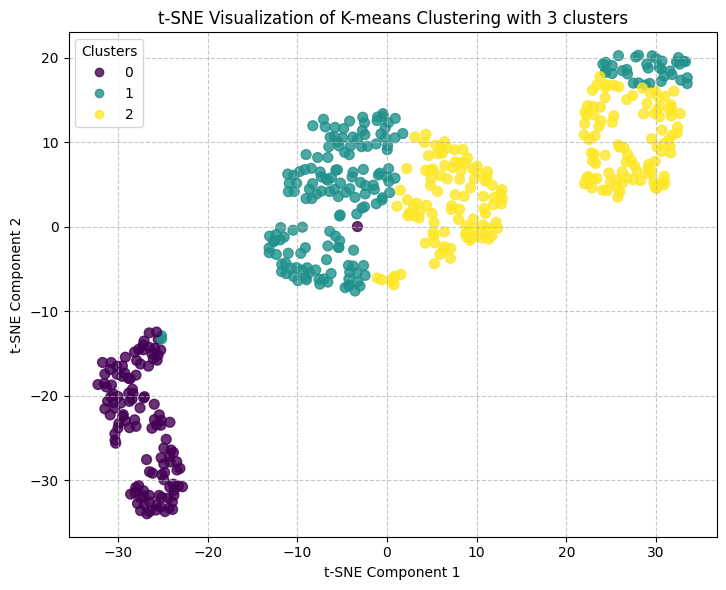

In [ ]:
print("Computing t-SNE embedding (this may take a moment)...")
tsne = TSNE(n_components=2, perplexity=30, n_iter=1000, random_state=42)
X_tsne = tsne.fit_transform(X_scaled)
plt.figure(figsize=(14, 6))
plt.subplot(1, 2, 2)
scatter = plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=kmeans_model.labels_, cmap='viridis', s=50, alpha=0.8)
plt.title(f't-SNE Visualization of K-means Clustering with {n_clusters} clusters')
plt.xlabel('t-SNE Component 1')
plt.ylabel('t-SNE Component 2')
plt.legend(*scatter.legend_elements(), title="Clusters")
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

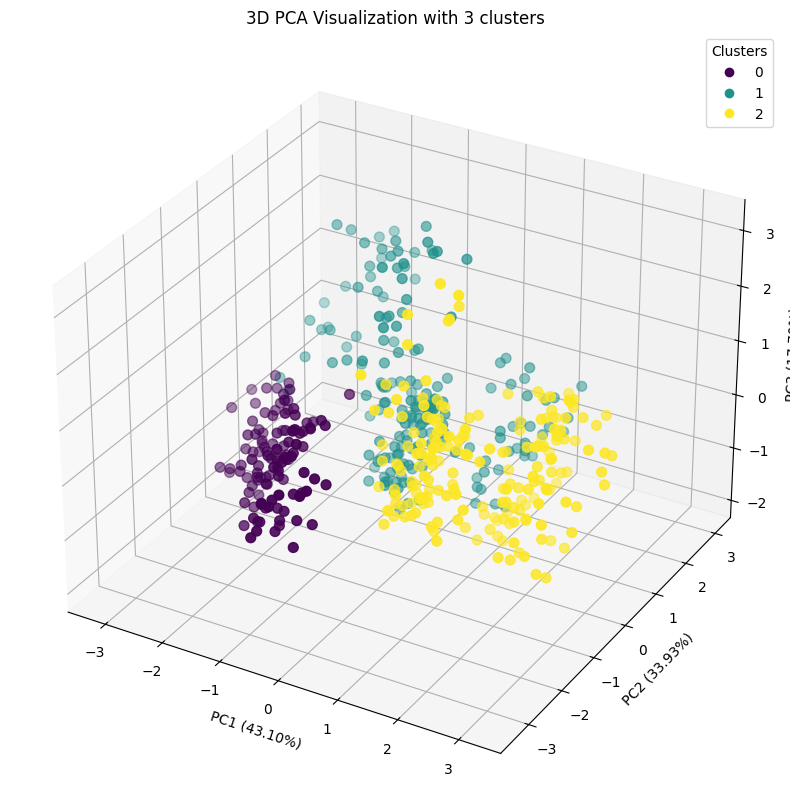

In [ ]:
pca_3d = PCA(n_components=3)
X_pca_3d = pca_3d.fit_transform(X_scaled)

fig = plt.figure(figsize=(12, 10))
ax = fig.add_subplot(111, projection='3d')

scatter = ax.scatter(
    X_pca_3d[:, 0],
    X_pca_3d[:, 1],
    X_pca_3d[:, 2],
    c=kmeans_model.labels_,
    cmap='viridis',
    s=50
)

ax.set_xlabel(f'PC1 ({pca_3d.explained_variance_ratio_[0]:.2%})')
ax.set_ylabel(f'PC2 ({pca_3d.explained_variance_ratio_[1]:.2%})')
ax.set_zlabel(f'PC3 ({pca_3d.explained_variance_ratio_[2]:.2%})')
plt.title(f'3D PCA Visualization with {n_clusters} clusters')
plt.legend(*scatter.legend_elements(), title="Clusters")
plt.show()

In [ ]:
cluster_counts = df_with_clusters_3['Cluster'].value_counts().sort_index()
print("\nCluster Distribution:")
for cluster, count in cluster_counts.items():
    print(f"Cluster {cluster}: {count} samples ({count/len(df_with_clusters_3)*100:.2f}%)")

print("\nCluster Statistics (means of each feature per cluster):")
cluster_means = df_with_clusters_3.groupby('Cluster')[features].mean()
print(cluster_means)


Cluster Distribution:
Cluster 0: 119 samples (23.80%)
Cluster 1: 184 samples (36.80%)
Cluster 2: 197 samples (39.40%)

Cluster Statistics (means of each feature per cluster):
              balance  avg_spending       salary  savings_rate  responsiveness
Cluster                                                                       
0         6668.634706   3672.768571  5051.201681      0.014613        0.194370
1        11214.022391   4622.766413  6522.358696      0.030114        0.657446
2         9596.223959   2323.309594  3966.989848      0.039218        0.741421


Cluster 2: cashback; cluster 1: auto_save_offer; cluster 0: none and reminder at random

To understand how effective these policies are, compare them with a random policy

Call the simulator and look at the results of the policies

Simulating 8-cluster policy...
Simulating 3-cluster policy...
Simulating Random policy...

Policy Comparison Table:
   policy  total_reward  avg_reward_per_customer  churn_rate  num_churned
8-cluster  132041474.80             264082.94960         5.4           27
3-cluster  128855159.63             257710.31926         5.6           28
   Random   91320142.20             182640.28440         5.0           25


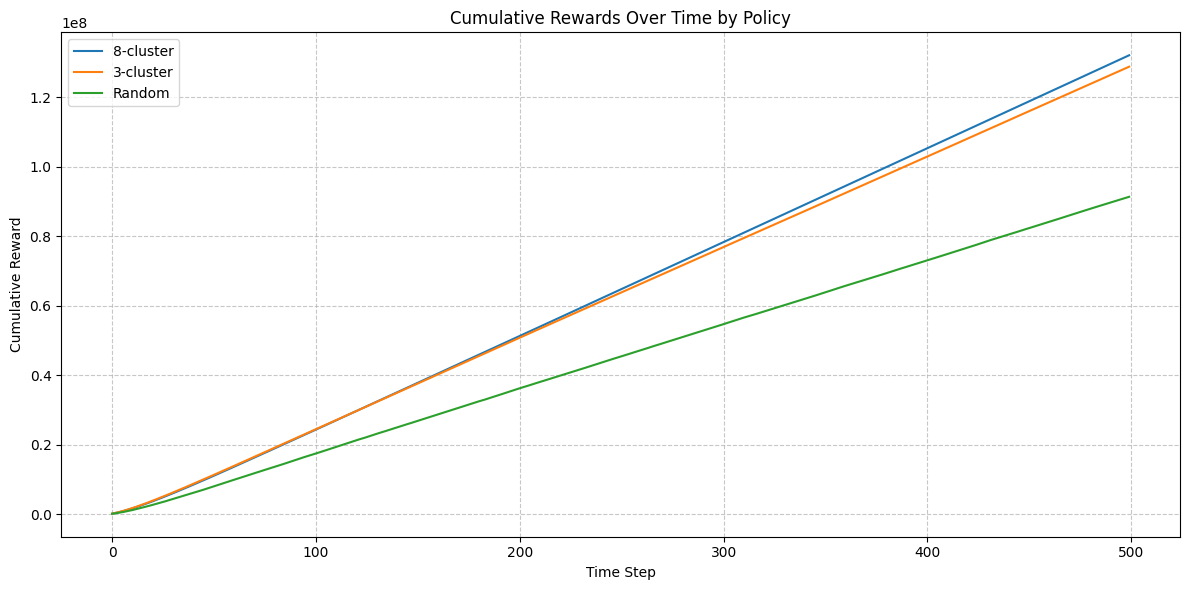

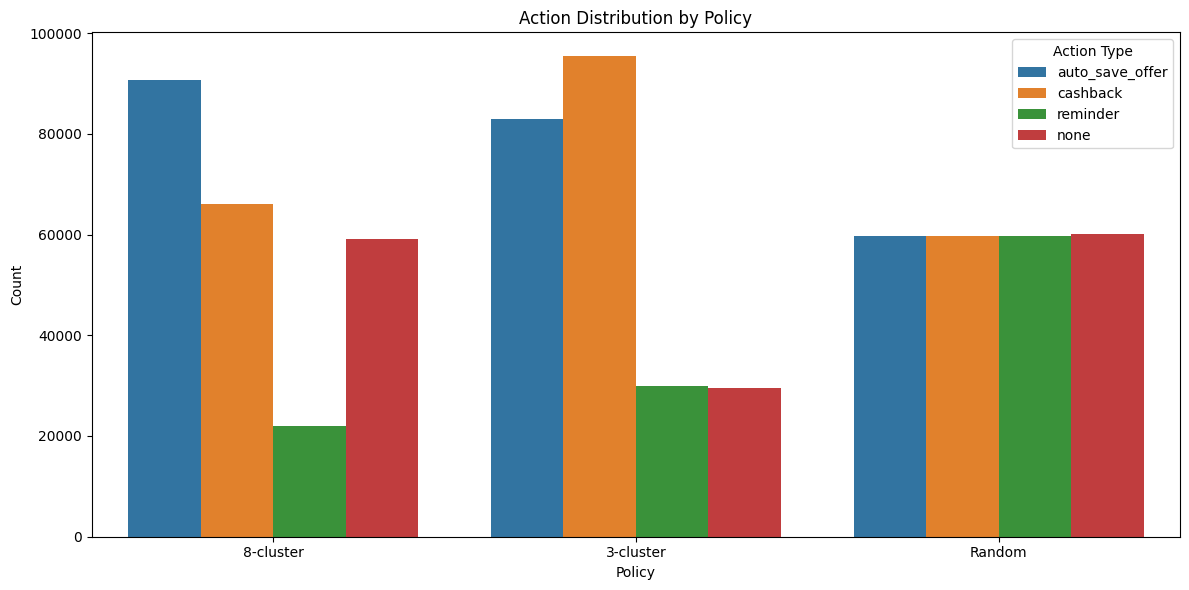

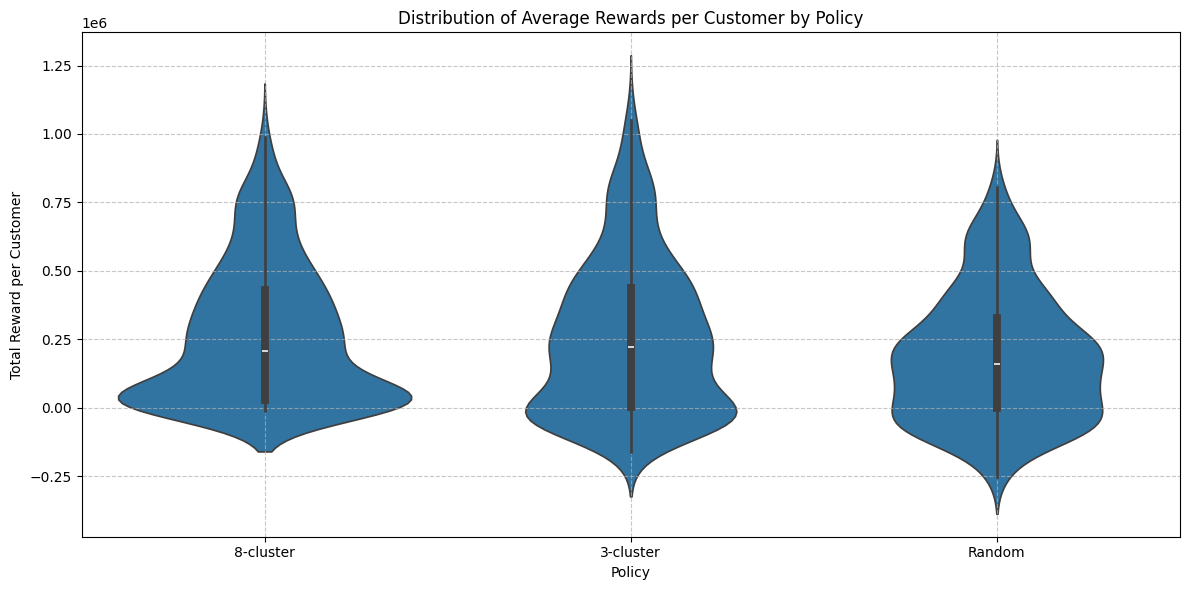

In [ ]:
spec = importlib.util.spec_from_file_location("simulator", "simulator.cpython-39.pyc")
simulator_module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(simulator_module)

actions = ['auto_save_offer', 'cashback', 'reminder', 'none']

cluster_8_actions = {
    0: 'auto_save_offer',
    1: 'cashback',
    2: 'none',
    3: 'auto_save_offer',
    4: 'reminder',
    5: 'none',
    6: 'cashback',
    7: 'reminder'
}

cluster_3_actions = {
    0: lambda: random.choice(['none', 'reminder']),
    1: 'auto_save_offer',
    2: 'cashback'
}

def random_policy():
    return random.choice(actions)

def simulate_policy(policy_name, policy_func, num_steps=500):
    total_rewards = []
    churn_counts = []

    customer_ids = df_with_clusters_8['customer_id'].unique()
    for customer_id in customer_ids:
        env = simulator_module.CustomerEnvironment(df_with_clusters_8)
        customer_rewards = []
        churned = False

        for step in range(num_steps):
            if policy_name == '8-cluster':
                cluster = df_with_clusters_8.loc[df_with_clusters_8['customer_id'] == customer_id, 'Cluster'].iloc[0]
                action = cluster_8_actions[cluster]
            elif policy_name == '3-cluster':
                cluster = df_with_clusters_3.loc[df_with_clusters_3['customer_id'] == customer_id, 'Cluster'].iloc[0]
                action = cluster_3_actions[cluster]() if callable(cluster_3_actions[cluster]) else cluster_3_actions[cluster]
            else:
                action = policy_func()

            try:
                state, reward = env.step(customer_id=customer_id, action=action)
                customer_rewards.append(reward)

                if state['churned']:
                    churned = True
                    break
            except Exception as e:
                print(f"Error for customer {customer_id}, step {step}: {e}")
                break

        total_rewards.append(sum(customer_rewards))
        churn_counts.append(1 if churned else 0)

    return {
        'policy': policy_name,
        'total_reward': sum(total_rewards),
        'avg_reward_per_customer': np.mean(total_rewards) if total_rewards else 0,
        'churn_rate': np.mean(churn_counts) * 100 if churn_counts else 0,
        'num_churned': sum(churn_counts),
        'rewards_per_customer': total_rewards
    }

def collect_visualization_data(policy_name, policy_func, num_steps=500):
    action_counts = {action: 0 for action in actions}

    cumulative_rewards_over_time = np.zeros(num_steps)

    customer_ids = df_with_clusters_8['customer_id'].unique()

    for customer_id in customer_ids:
        env = simulator_module.CustomerEnvironment(df_with_clusters_8)
        churned = False

        for step in range(num_steps):
            if churned:
                break

            if policy_name == '8-cluster':
                cluster = df_with_clusters_8.loc[df_with_clusters_8['customer_id'] == customer_id, 'Cluster'].iloc[0]
                action = cluster_8_actions[cluster]
            elif policy_name == '3-cluster':
                cluster = df_with_clusters_3.loc[df_with_clusters_3['customer_id'] == customer_id, 'Cluster'].iloc[0]
                action = cluster_3_actions[cluster]() if callable(cluster_3_actions[cluster]) else cluster_3_actions[cluster]
            else:
                action = policy_func()

            action_counts[action] += 1

            try:
                state, reward = env.step(customer_id=customer_id, action=action)

                if step < num_steps:
                    cumulative_rewards_over_time[step] += reward

                if state['churned']:
                    churned = True
            except Exception as e:
                break

    cumulative_sum_rewards = np.cumsum(cumulative_rewards_over_time)

    return {
        'action_counts': action_counts,
        'cumulative_rewards': cumulative_sum_rewards
    }

policies = [
    ('8-cluster', lambda: None),
    ('3-cluster', lambda: None),
    ('Random', random_policy)
]

results = []
for policy_name, policy_func in policies:
    print(f"Simulating {policy_name} policy...")
    result = simulate_policy(policy_name, policy_func, num_steps=500)
    results.append(result)

results_df = pd.DataFrame(results)

print("\nPolicy Comparison Table:")
print(results_df[['policy', 'total_reward', 'avg_reward_per_customer', 'churn_rate', 'num_churned']].to_string(index=False))

rewards_distribution_data = {}

for policy_name, policy_func in policies:
    result = simulate_policy(policy_name, policy_func, num_steps=500)
    results.append(result)
    rewards_distribution_data[policy_name] = result['rewards_per_customer']

results_df = pd.DataFrame(results)

cumulative_rewards_data = {}
action_distribution_data = {}

for policy_name, policy_func in policies:
    viz_data = collect_visualization_data(policy_name, policy_func, num_steps=500)
    cumulative_rewards_data[policy_name] = viz_data['cumulative_rewards']
    action_distribution_data[policy_name] = viz_data['action_counts']

plt.figure(figsize=(12, 6))
for policy_name, rewards in cumulative_rewards_data.items():
    plt.plot(range(len(rewards)), rewards, label=policy_name)
plt.title('Cumulative Rewards Over Time by Policy')
plt.xlabel('Time Step')
plt.ylabel('Cumulative Reward')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 6))
action_data = []
for policy_name, action_counts in action_distribution_data.items():
    for action, count in action_counts.items():
        action_data.append({
            'Policy': policy_name,
            'Action': action,
            'Count': count
        })

action_df = pd.DataFrame(action_data)
sns.barplot(x='Policy', y='Count', hue='Action', data=action_df)
plt.title('Action Distribution by Policy')
plt.xlabel('Policy')
plt.ylabel('Count')
plt.legend(title='Action Type')
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 6))
rewards_data = []
for policy_name, rewards in rewards_distribution_data.items():
    for reward in rewards:
        rewards_data.append({
            'Policy': policy_name,
            'Reward': reward
        })

rewards_df = pd.DataFrame(rewards_data)
sns.violinplot(x='Policy', y='Reward', data=rewards_df)
plt.title('Distribution of Average Rewards per Customer by Policy')
plt.xlabel('Policy')
plt.ylabel('Total Reward per Customer')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

The analysis shows that the policy built on 8 clusters has the best result (maximum total reward). We can break these clusters down further and look at the behavior by segment, which will let us see for which groups the logic is relatively right and for which it is less so.

The best performing policy based on total reward is: 8-cluster

Segment Analysis for Policy with Highest Total Reward:
   Cluster            Offer  Average Reward  Churn Rate
0        0  auto_save_offer   207418.514646    0.000000
1        1         cashback   234684.509672    0.000000
2        2             none    14773.648169    2.816901
3        3  auto_save_offer   116237.285412    3.529412
4        4         reminder    25755.216923   38.461538
5        5             none     7785.648776    0.000000
6        6         cashback   427462.991972    0.000000
7        7         reminder    20561.748800   28.000000


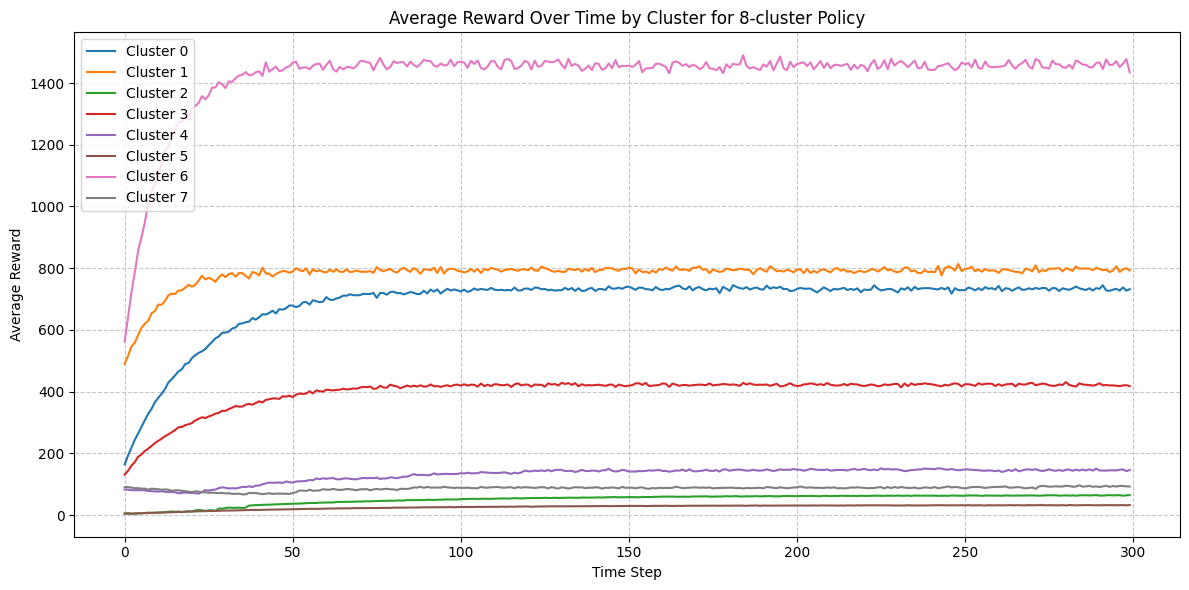

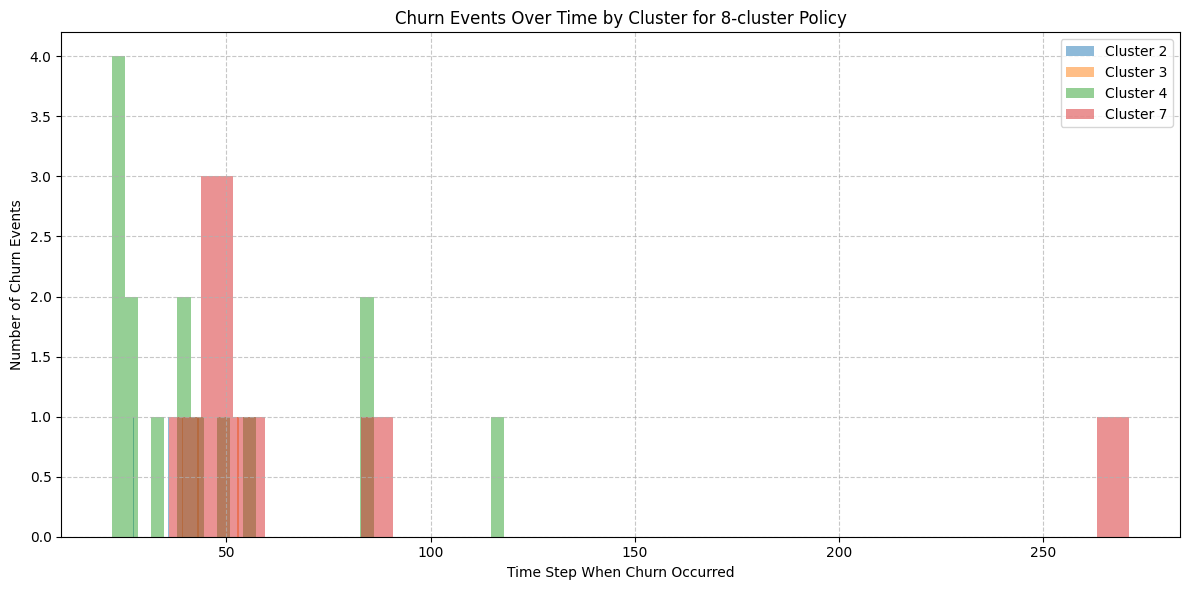

In [ ]:
best_policy_name = results_df.loc[results_df['total_reward'].idxmax(), 'policy']
print(f"The best performing policy based on total reward is: {best_policy_name}")

def analyze_policy_by_segments(policy_name):
    if policy_name == '8-cluster':
        df_with_clusters = df_with_clusters_8
        cluster_actions = cluster_8_actions
        num_clusters = 8
    elif policy_name == '3-cluster':
        df_with_clusters = df_with_clusters_3
        cluster_actions = cluster_3_actions
        num_clusters = 3
    else:
        print("Random policy doesn't have well-defined segments. Using 8-cluster segmentation for analysis.")
        df_with_clusters = df_with_clusters_8
        cluster_actions = {i: 'random' for i in range(8)}
        num_clusters = 8

    segment_results = []
    segment_rewards_over_time = {}
    segment_churn_over_time = {}

    for cluster in range(num_clusters):
        cluster_customers = df_with_clusters[df_with_clusters['Cluster'] == cluster]['customer_id'].unique()

        if len(cluster_customers) == 0:
            continue

        if callable(cluster_actions.get(cluster, None)):
            action = "Random choice: none/reminder"
        else:
            action = cluster_actions.get(cluster, "random")

        total_reward = 0
        churn_count = 0
        customer_rewards = []
        all_rewards_over_time = []
        churns_over_time = []

        for customer_id in cluster_customers:
            env = simulator_module.CustomerEnvironment(df_with_clusters)
            rewards = []
            churned = False

            for step in range(300):
                if policy_name == '8-cluster':
                    act = cluster_8_actions[cluster]
                elif policy_name == '3-cluster':
                    act = cluster_3_actions[cluster]() if callable(cluster_3_actions[cluster]) else cluster_3_actions[cluster]
                else:
                    act = random_policy()

                try:
                    state, reward = env.step(customer_id=customer_id, action=act)
                    rewards.append(reward)

                    if state['churned']:
                        churned = True
                        churns_over_time.append(step)
                        break
                except Exception as e:
                    break

            customer_total_reward = sum(rewards)
            total_reward += customer_total_reward
            customer_rewards.append(customer_total_reward)
            all_rewards_over_time.extend([(step, r) for step, r in enumerate(rewards)])
            churn_count += 1 if churned else 0

        segment_size = len(cluster_customers)
        avg_reward = total_reward / segment_size if segment_size > 0 else 0
        churn_rate = (churn_count / segment_size) * 100 if segment_size > 0 else 0

        segment_results.append({
            'Cluster': cluster,
            'Offer': action,
            'Size': segment_size,
            'Total Reward': total_reward,
            'Average Reward': avg_reward,
            'Churn Rate': churn_rate,
            'Churn Count': churn_count
        })

        segment_rewards_over_time[cluster] = all_rewards_over_time
        segment_churn_over_time[cluster] = churns_over_time

    return pd.DataFrame(segment_results), segment_rewards_over_time, segment_churn_over_time

segment_analysis, rewards_over_time, churns_over_time = analyze_policy_by_segments(best_policy_name)

print("\nSegment Analysis for Policy with Highest Total Reward:")
print(segment_analysis[['Cluster', 'Offer', 'Average Reward', 'Churn Rate']])

plt.figure(figsize=(12, 6))
for cluster, rewards in rewards_over_time.items():
    if rewards:
        steps, values = zip(*rewards)
        rewards_df = pd.DataFrame({'step': steps, 'reward': values})
        avg_rewards = rewards_df.groupby('step').mean().reset_index()
        plt.plot(avg_rewards['step'], avg_rewards['reward'], label=f'Cluster {cluster}')

plt.title(f'Average Reward Over Time by Cluster for {best_policy_name} Policy')
plt.xlabel('Time Step')
plt.ylabel('Average Reward')
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 6))
for cluster, churn_steps in churns_over_time.items():
    if churn_steps:
        plt.hist(churn_steps, bins=30, alpha=0.5, label=f'Cluster {cluster}')

plt.title(f'Churn Events Over Time by Cluster for {best_policy_name} Policy')
plt.xlabel('Time Step When Churn Occurred')
plt.ylabel('Number of Churn Events')
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()
plt.tight_layout()
plt.show()

Clusters 4 and 7 have a low average reward and a high churn rate. Clusters 0, 1 and 6 show good numbers, which means that cashback and auto_save_offer work well on highly responsive customers.

We can do a similar analysis for the policy built on 3 clusters

Analyzing policy: 3-cluster

Segment Analysis for 3-Cluster Policy:
   Cluster                         Offer  Average Reward  Churn Rate
0        0  Random choice: none/reminder   -26651.431933    0.000000
1        1               auto_save_offer   215019.025978   10.326087
2        2                      cashback   204493.972234    3.553299


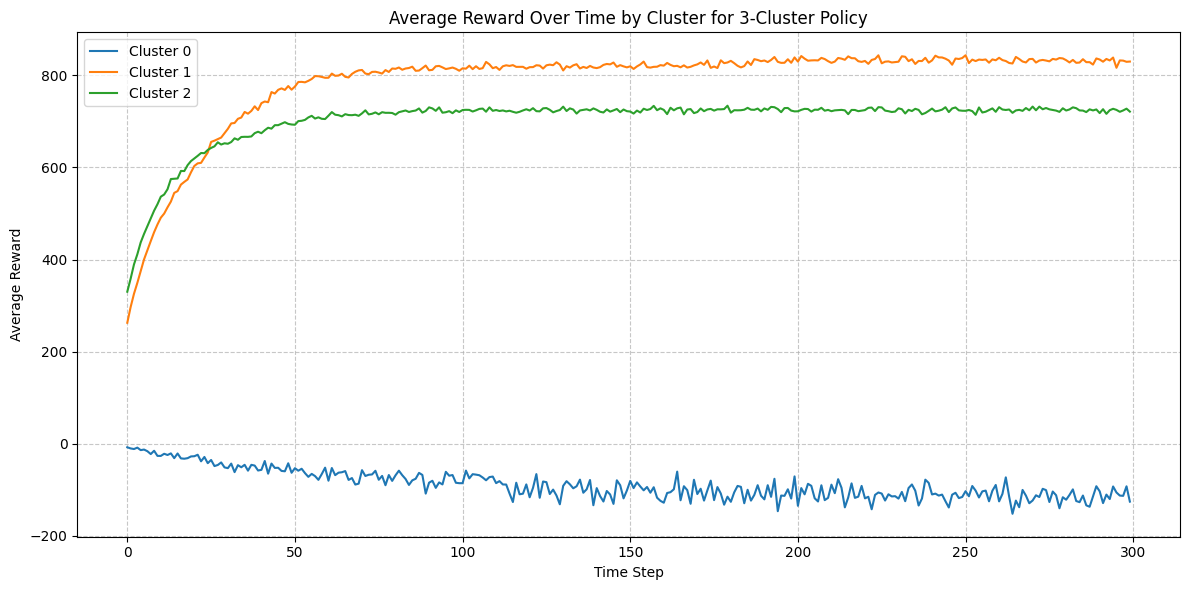

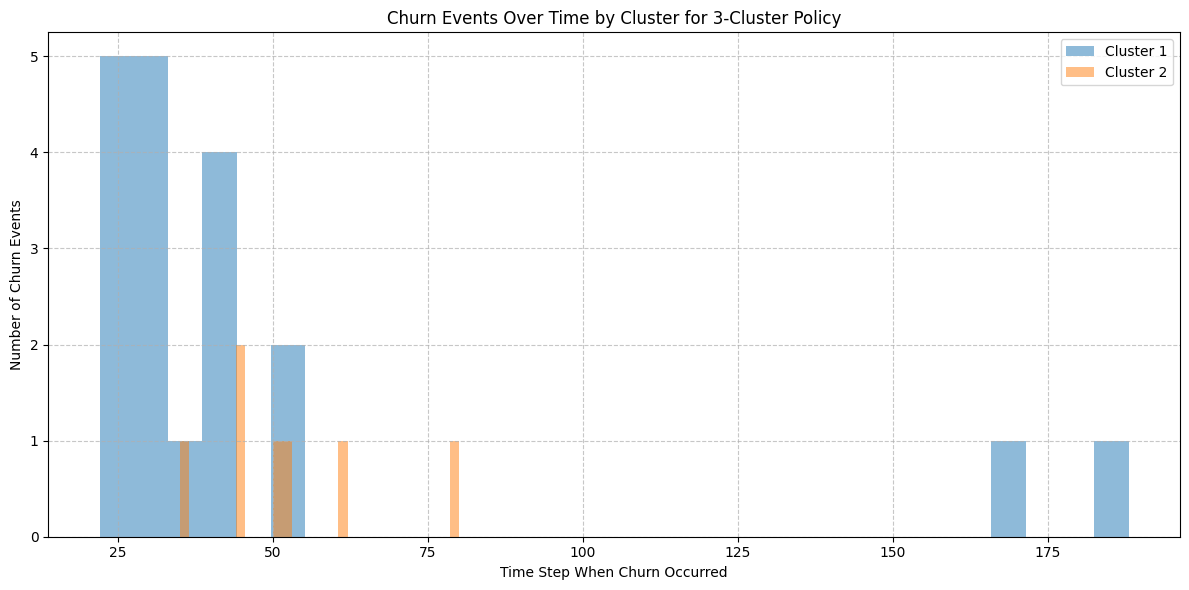

In [ ]:
policy_name = '3-cluster'
print(f"Analyzing policy: {policy_name}")

def analyze_3_cluster_policy():
    df_with_clusters = df_with_clusters_3
    cluster_actions = cluster_3_actions
    num_clusters = 3

    segment_results = []
    segment_rewards_over_time = {}
    segment_churn_over_time = {}

    for cluster in range(num_clusters):
        cluster_customers = df_with_clusters[df_with_clusters['Cluster'] == cluster]['customer_id'].unique()
        if len(cluster_customers) == 0:
            continue

        action = (
            "Random choice: none/reminder"
            if callable(cluster_actions.get(cluster))
            else cluster_actions.get(cluster, "random")
        )

        total_reward = 0
        churn_count = 0
        customer_rewards = []
        all_rewards_over_time = []
        churns_over_time = []

        for customer_id in cluster_customers:
            env = simulator_module.CustomerEnvironment(df_with_clusters)
            rewards = []
            churned = False

            for step in range(300):
                act = cluster_3_actions[cluster]() if callable(cluster_3_actions[cluster]) else cluster_3_actions[cluster]

                try:
                    state, reward = env.step(customer_id=customer_id, action=act)
                    rewards.append(reward)

                    if state['churned']:
                        churned = True
                        churns_over_time.append(step)
                        break
                except:
                    break

            customer_total_reward = sum(rewards)
            total_reward += customer_total_reward
            customer_rewards.append(customer_total_reward)
            all_rewards_over_time.extend([(step, r) for step, r in enumerate(rewards)])
            churn_count += 1 if churned else 0

        segment_size = len(cluster_customers)
        avg_reward = total_reward / segment_size if segment_size > 0 else 0
        churn_rate = (churn_count / segment_size) * 100 if segment_size > 0 else 0

        segment_results.append({
            'Cluster': cluster,
            'Offer': action,
            'Size': segment_size,
            'Total Reward': total_reward,
            'Average Reward': avg_reward,
            'Churn Rate': churn_rate,
            'Churn Count': churn_count
        })

        segment_rewards_over_time[cluster] = all_rewards_over_time
        segment_churn_over_time[cluster] = churns_over_time

    return pd.DataFrame(segment_results), segment_rewards_over_time, segment_churn_over_time

segment_analysis, rewards_over_time, churns_over_time = analyze_3_cluster_policy()

print("\nSegment Analysis for 3-Cluster Policy:")
print(segment_analysis[['Cluster', 'Offer', 'Average Reward', 'Churn Rate']])

plt.figure(figsize=(12, 6))
for cluster, rewards in rewards_over_time.items():
    if rewards:
        steps, values = zip(*rewards)
        rewards_df = pd.DataFrame({'step': steps, 'reward': values})
        avg_rewards = rewards_df.groupby('step')['reward'].mean().reset_index()
        plt.plot(avg_rewards['step'], avg_rewards['reward'], label=f'Cluster {cluster}')

plt.title('Average Reward Over Time by Cluster for 3-Cluster Policy')
plt.xlabel('Time Step')
plt.ylabel('Average Reward')
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 6))
for cluster, churn_steps in churns_over_time.items():
    if churn_steps:
        plt.hist(churn_steps, bins=30, alpha=0.5, label=f'Cluster {cluster}')

plt.title('Churn Events Over Time by Cluster for 3-Cluster Policy')
plt.xlabel('Time Step When Churn Occurred')
plt.ylabel('Number of Churn Events')
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()
plt.tight_layout()
plt.show()

It shows that cluster 0 groups together customers for whom none and reminder are not the optimal offer.

Now we can run the analysis for both clusterings and see, segment by segment, which policies would be optimal for maximizing total reward, while also keeping the churn rate under control for each offer.

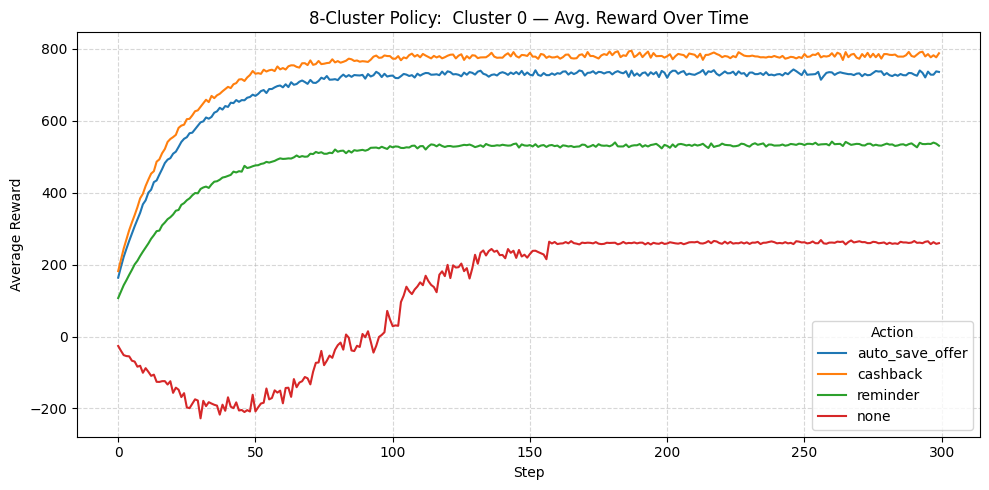

[Cluster 0 | auto_save_offer] no churns.
[Cluster 0 | cashback] no churns.
[Cluster 0 | reminder] no churns.


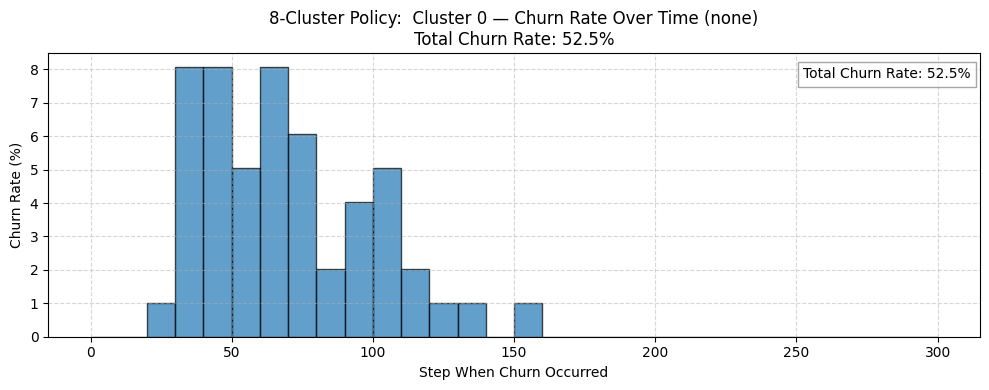

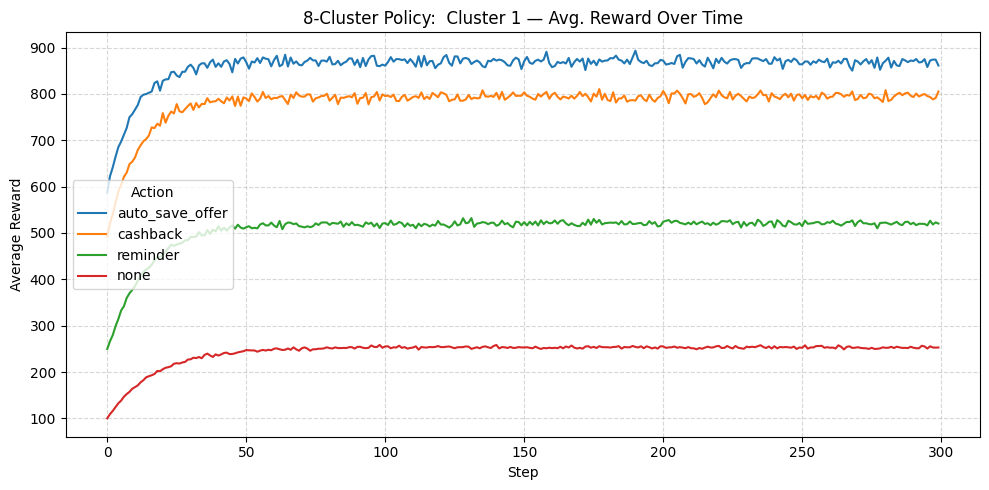

[Cluster 1 | auto_save_offer] no churns.
[Cluster 1 | cashback] no churns.
[Cluster 1 | reminder] no churns.
[Cluster 1 | none] no churns.


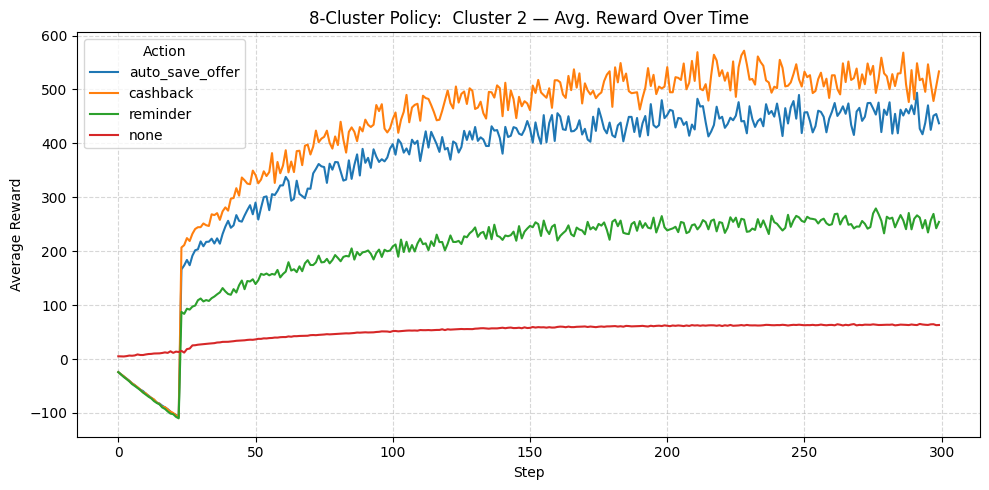

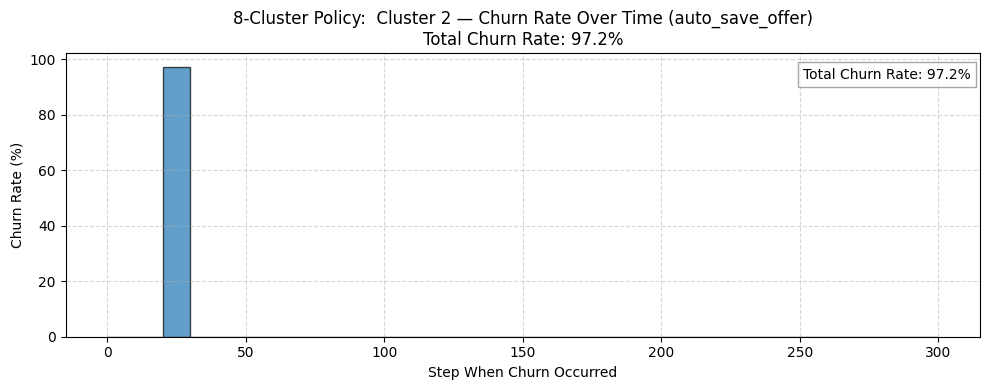

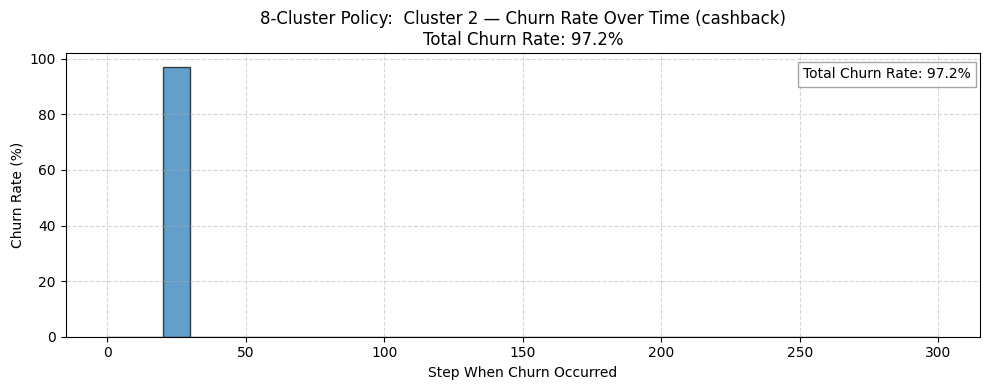

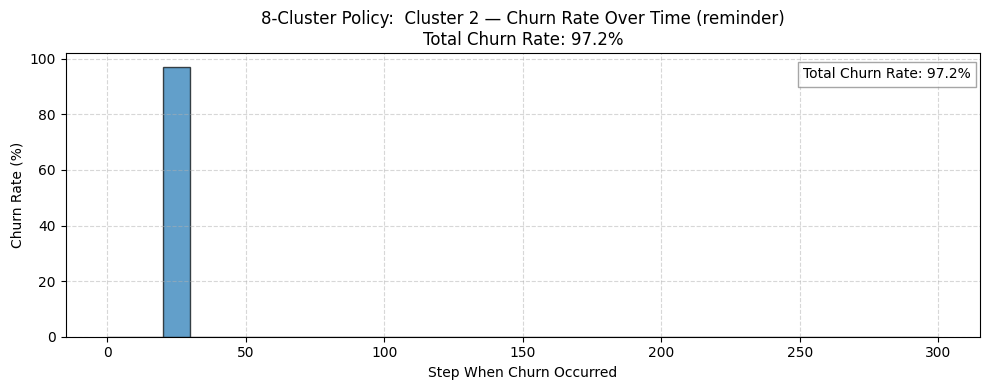

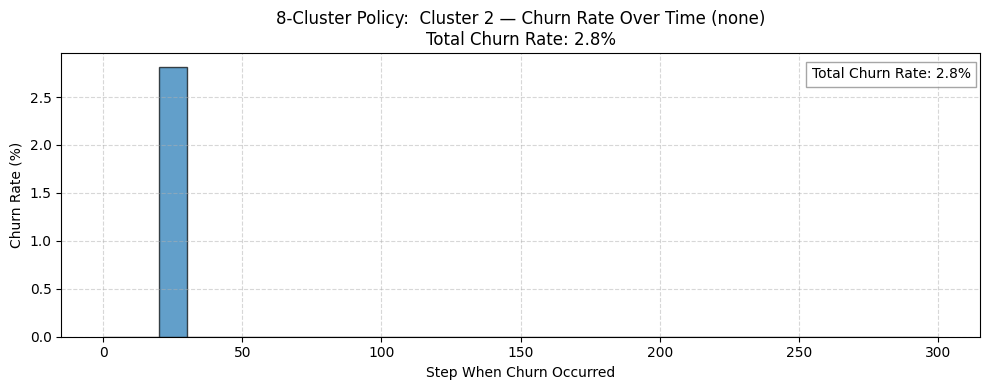

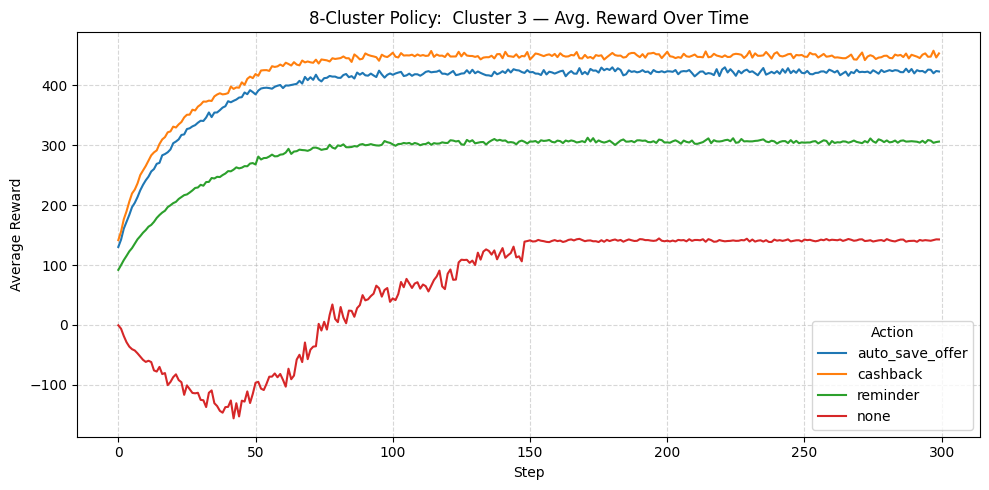

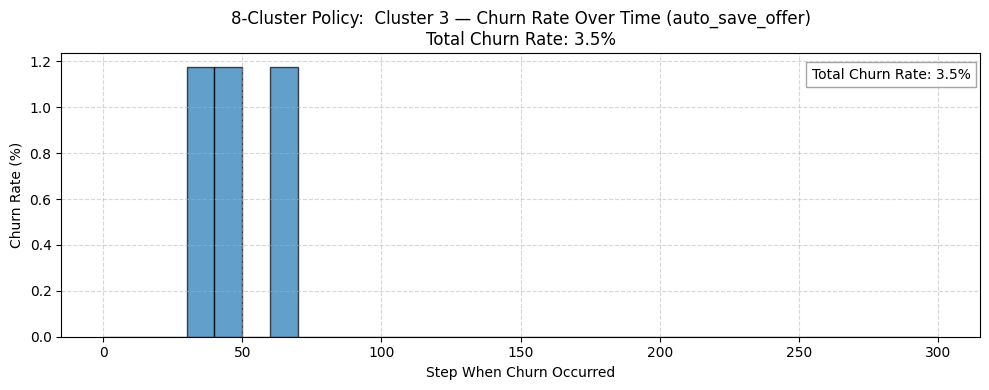

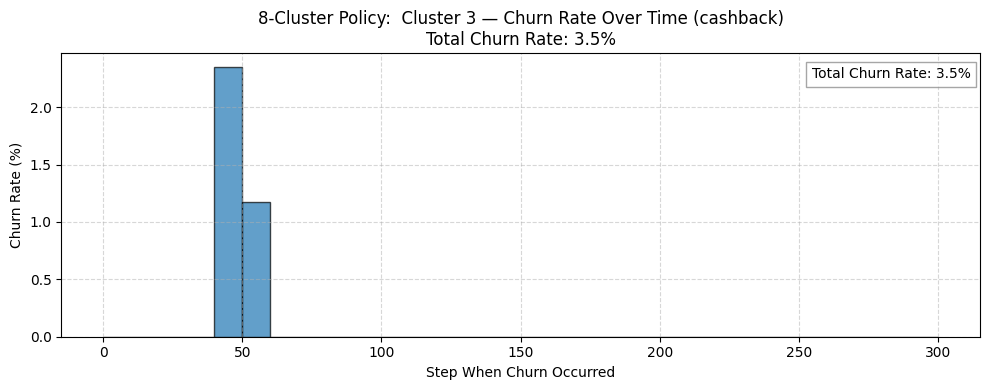

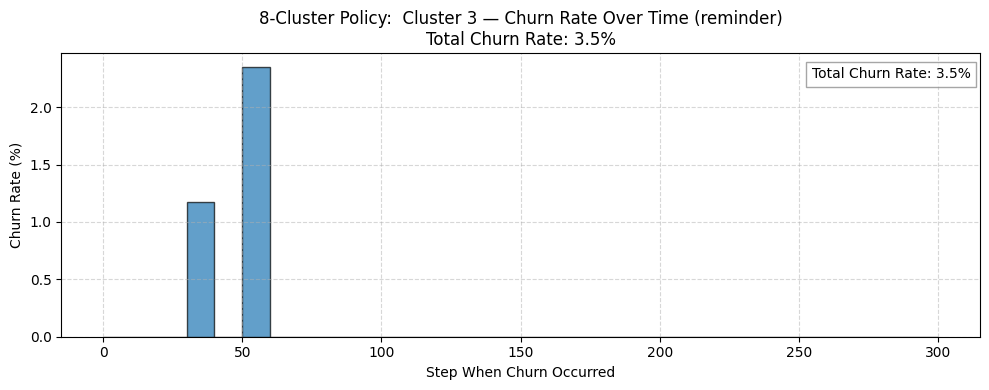

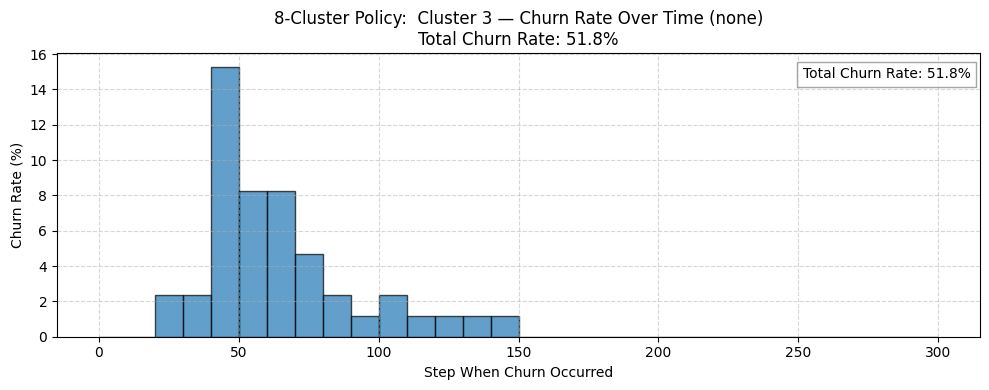

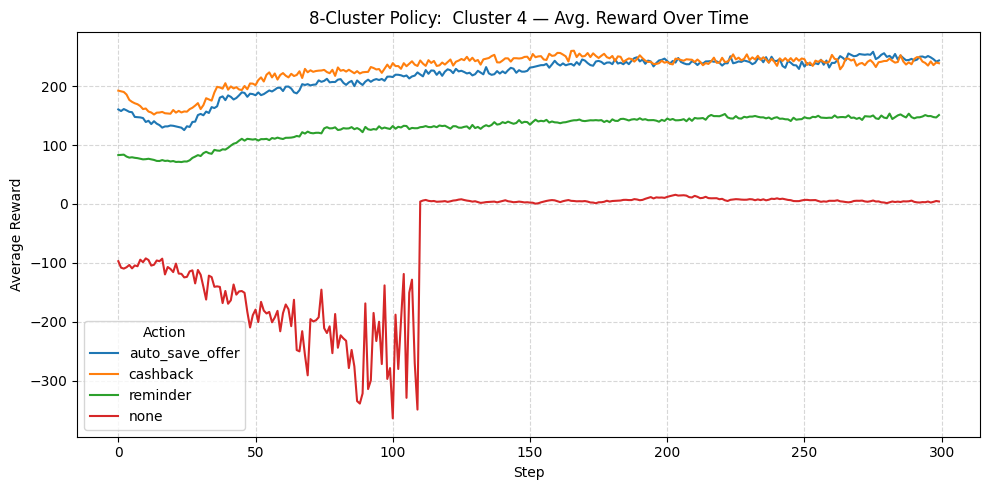

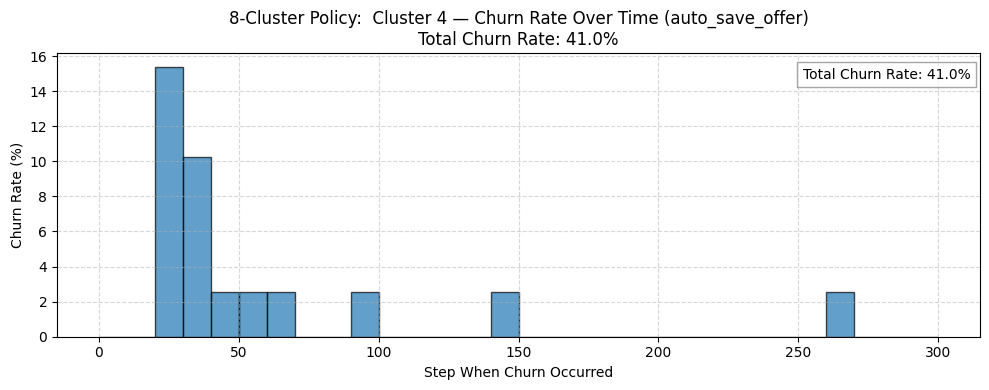

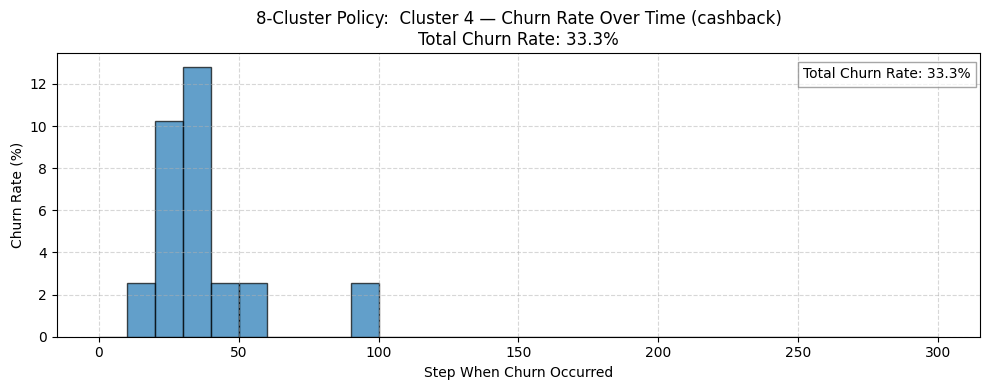

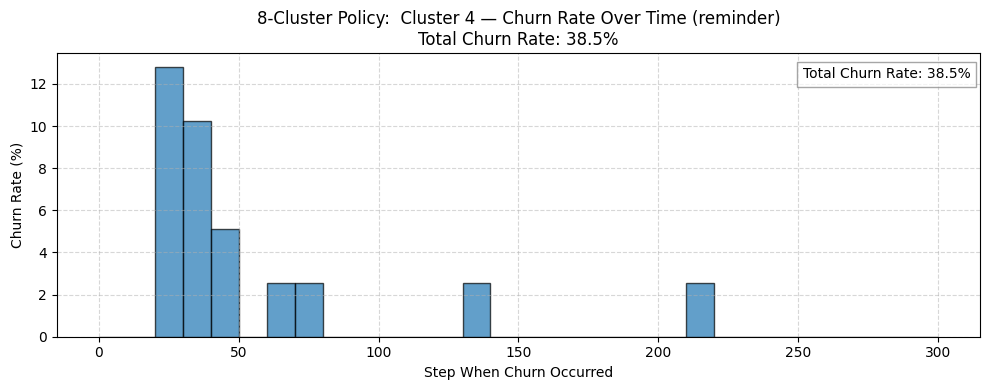

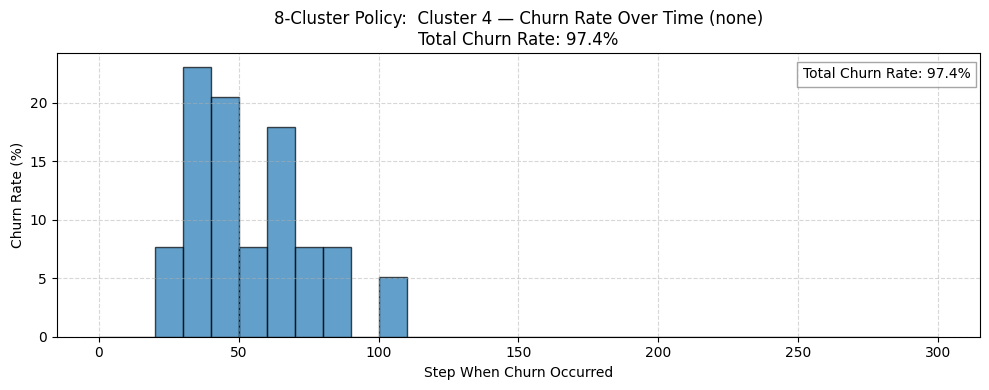

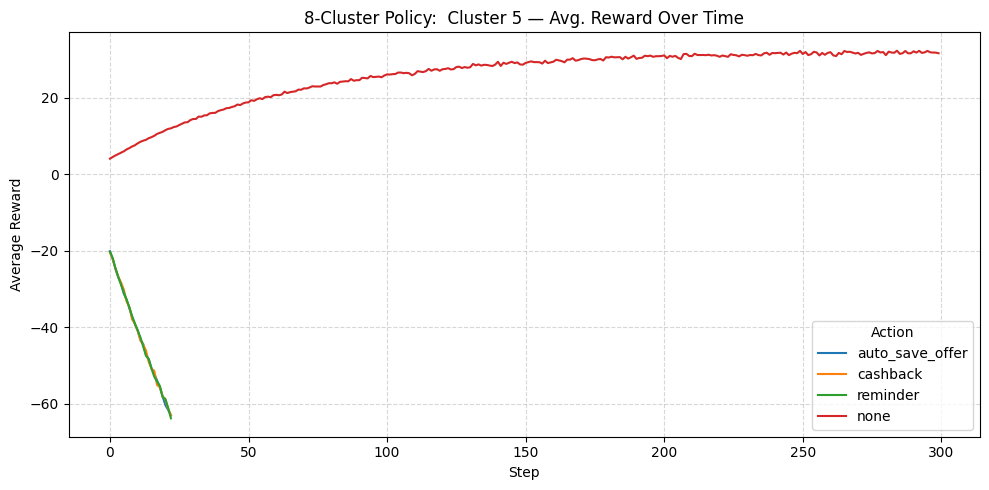

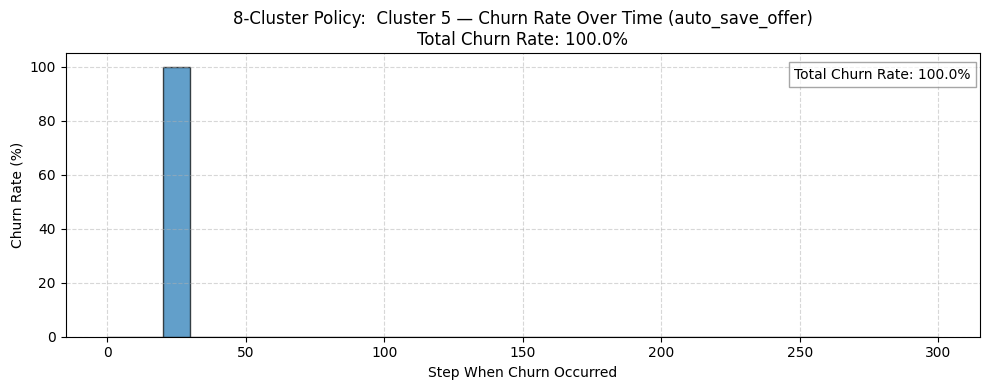

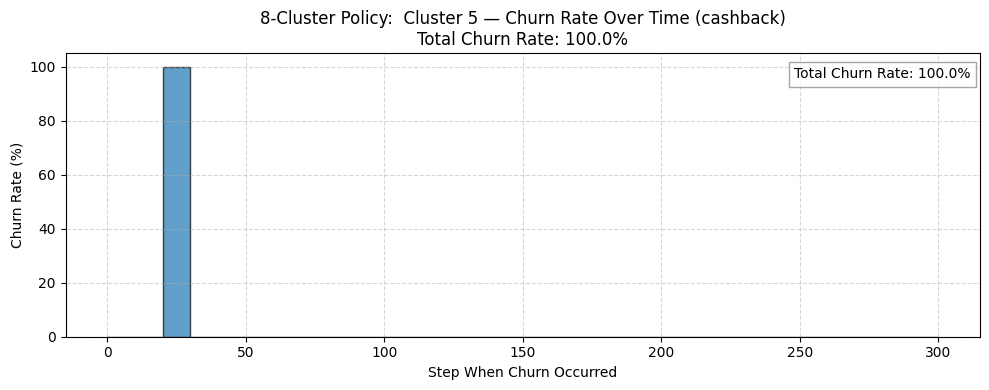

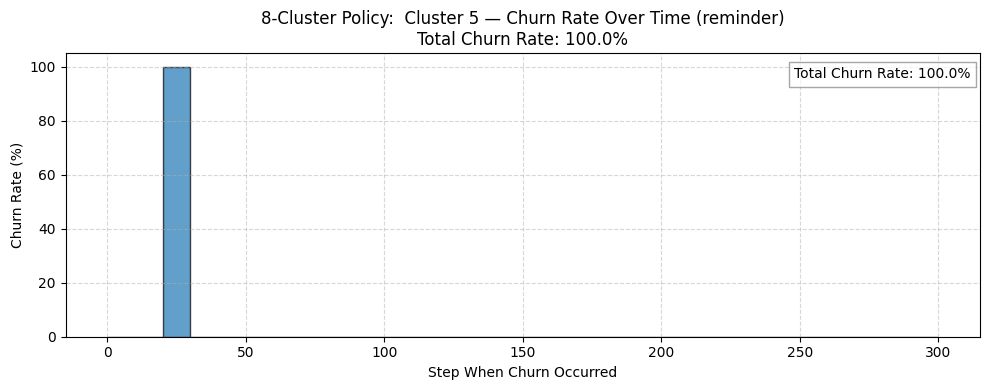

[Cluster 5 | none] no churns.


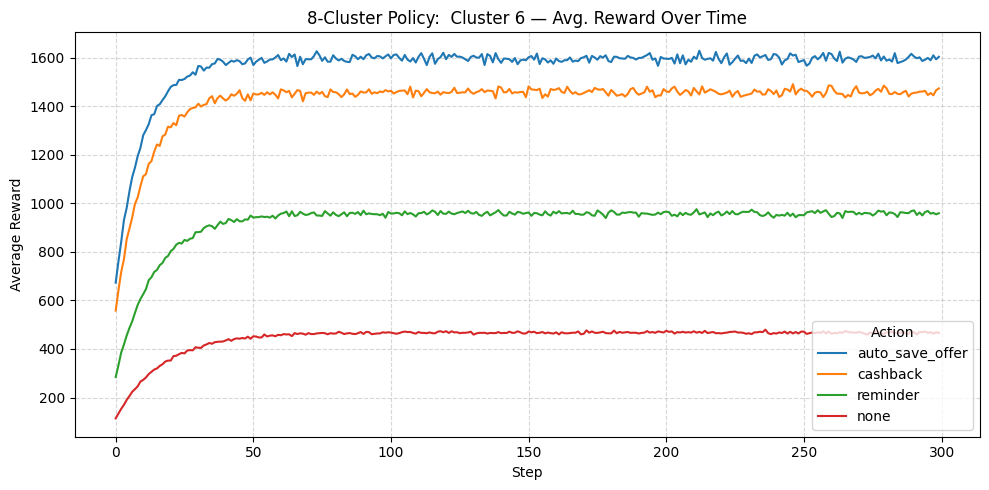

[Cluster 6 | auto_save_offer] no churns.
[Cluster 6 | cashback] no churns.
[Cluster 6 | reminder] no churns.
[Cluster 6 | none] no churns.


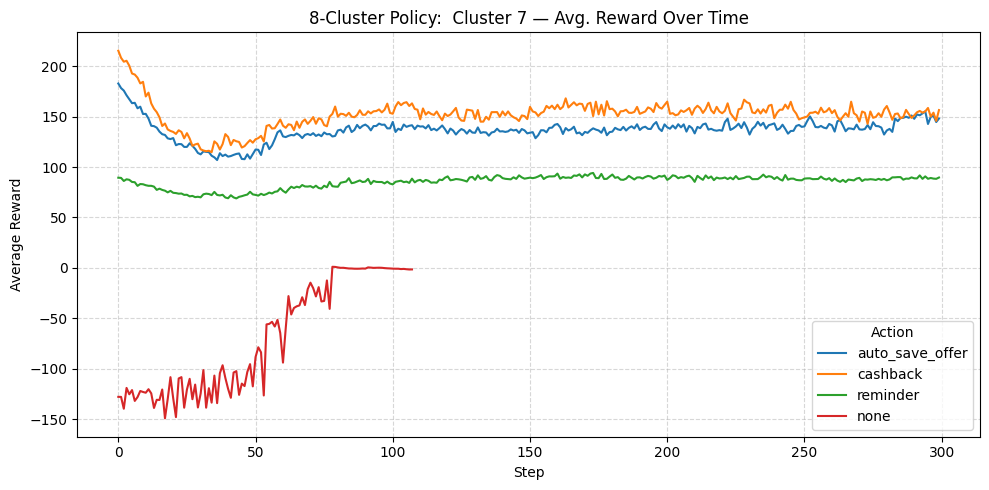

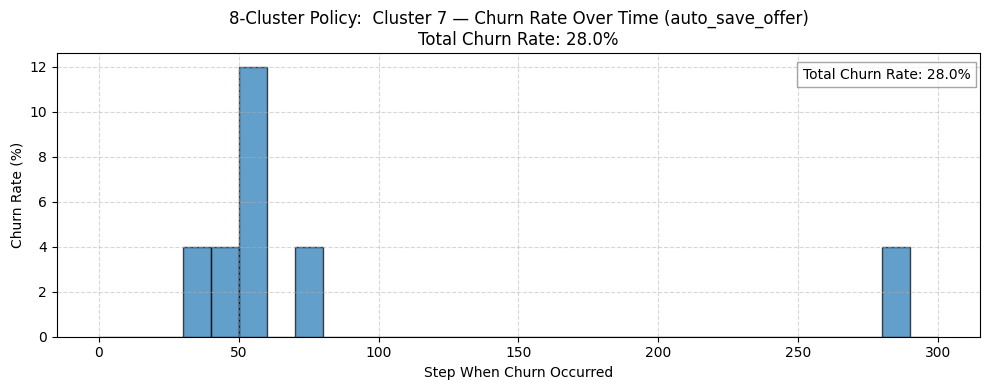

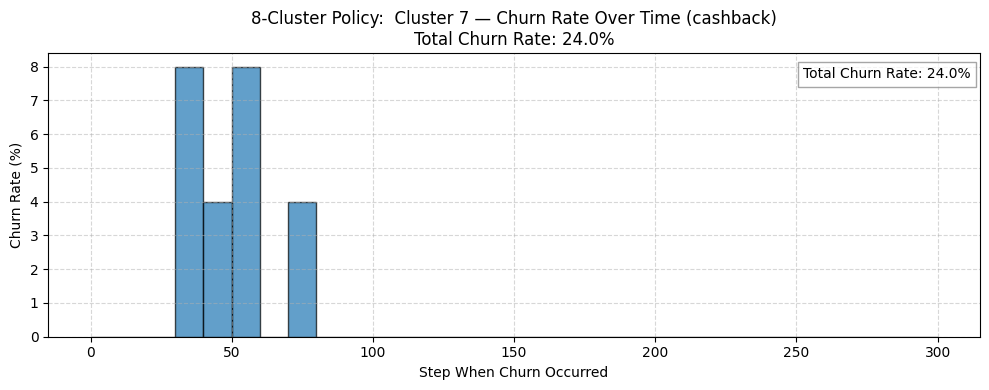

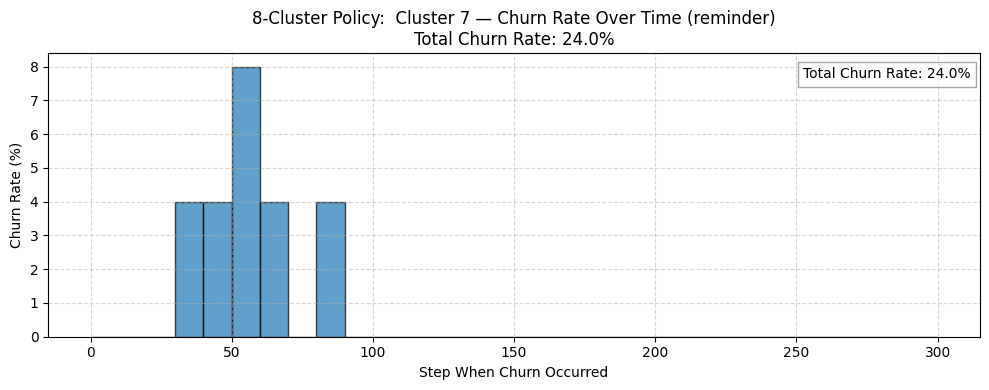

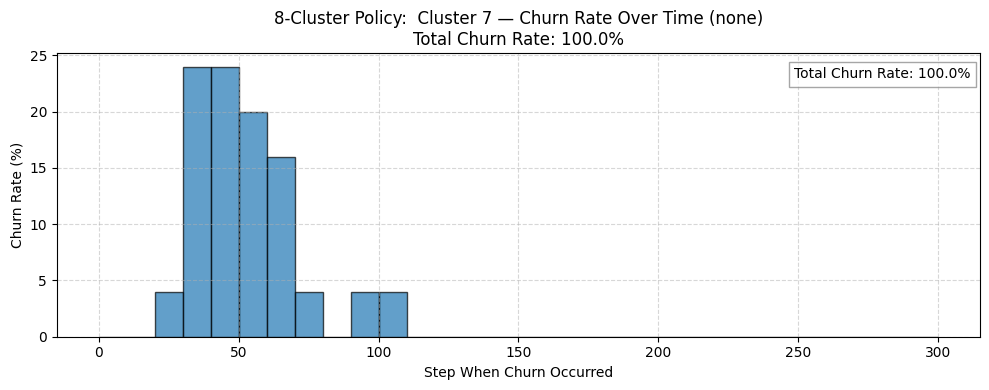

In [ ]:
actions = ['auto_save_offer', 'cashback', 'reminder', 'none']
clusters_to_analyze = list(range(8))
N_STEPS = 300

cluster_action_rewards = {}
cluster_action_churns = {}
cluster_sizes = {}

for cluster in clusters_to_analyze:
    cluster_customers = df_with_clusters_8[df_with_clusters_8['Cluster'] == cluster]['customer_id'].unique()
    cluster_size = len(cluster_customers)
    cluster_sizes[cluster] = cluster_size

    for action in actions:
        rewards_over_time = []
        churn_steps = []

        for customer_id in cluster_customers:
            env = simulator_module.CustomerEnvironment(df_with_clusters_8)
            churned = False

            for step in range(N_STEPS):
                if churned:
                    break
                try:
                    state, reward = env.step(customer_id=customer_id, action=action)
                    rewards_over_time.append((step, reward))

                    if state['churned']:
                        churn_steps.append(step)
                        churned = True
                        break
                except:
                    break

        cluster_action_rewards[(cluster, action)] = rewards_over_time
        cluster_action_churns[(cluster, action)] = churn_steps

for cluster in clusters_to_analyze:
    cluster_size = cluster_sizes[cluster]

    plt.figure(figsize=(10, 5))
    for action in actions:
        data = cluster_action_rewards.get((cluster, action), [])
        if not data:
            continue
        df = pd.DataFrame(data, columns=['step', 'reward'])
        avg = df.groupby('step')['reward'].mean().reset_index()
        plt.plot(avg['step'], avg['reward'], label=action)
    plt.title(f'8-Cluster Policy:  Cluster {cluster} - Avg Reward Over Time')
    plt.xlabel('Step')
    plt.ylabel('Average Reward')
    plt.legend(title='Action')
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

    for action in actions:
        churn_steps = cluster_action_churns.get((cluster, action), [])
        if not churn_steps:
            print(f"[Cluster {cluster} | {action}] no churns.")
            continue

        total_churn_rate = (len(churn_steps) / cluster_size) * 100

        plt.figure(figsize=(10, 4))
        plt.hist(
            churn_steps,
            bins=30,
            range=(0, N_STEPS),
            weights=[100 / cluster_size] * len(churn_steps),
            alpha=0.7,
            edgecolor='black'
        )

        plt.title(
            f'8-Cluster Policy:  Cluster {cluster} - Churn Rate Over Time ({action})\n'
            f'Total Churn Rate: {total_churn_rate:.1f}%'
        )
        plt.xlabel('Step When Churn Occurred')
        plt.ylabel('Churn Rate (%)')
        plt.grid(True, linestyle='--', alpha=0.5)
        plt.text(0.99, 0.95,
                 f'Total Churn Rate: {total_churn_rate:.1f}%',
                 transform=plt.gca().transAxes,
                 fontsize=10,
                 verticalalignment='top',
                 horizontalalignment='right',
                 bbox=dict(facecolor='white', alpha=0.7, edgecolor='gray'))
        plt.tight_layout()
        plt.show()

Based on the analysis, let's design a new optimal policy for each segment. In some clusters it is optimal to use one specific offer in the first steps and then switch.

Cluster 0: cashback

Cluster 1: auto_save_offer

Cluster 2: none for the first 25 steps, then cashback

Cluster 3: cashback

Cluster 4: cashback

Cluster 5: none

Cluster 6: auto_save_offer

Cluster 7: cashback

The same for 3 clusters

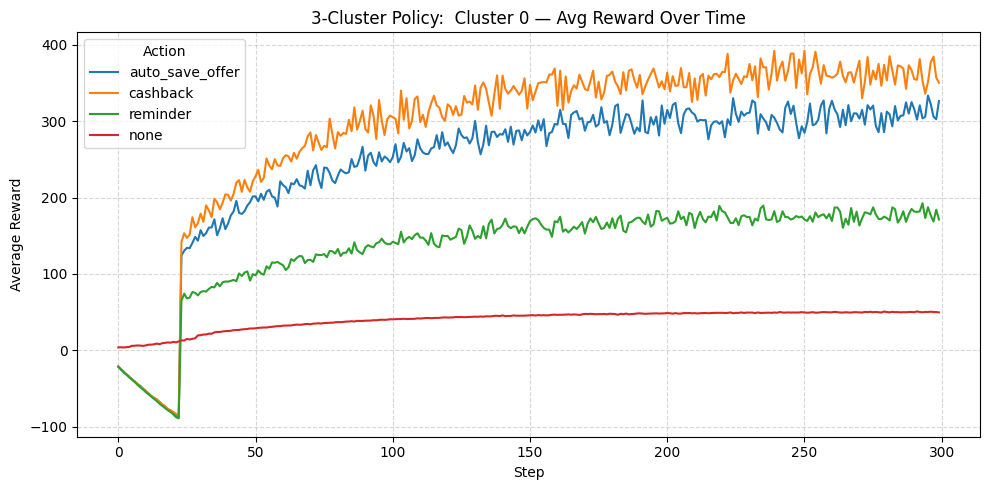

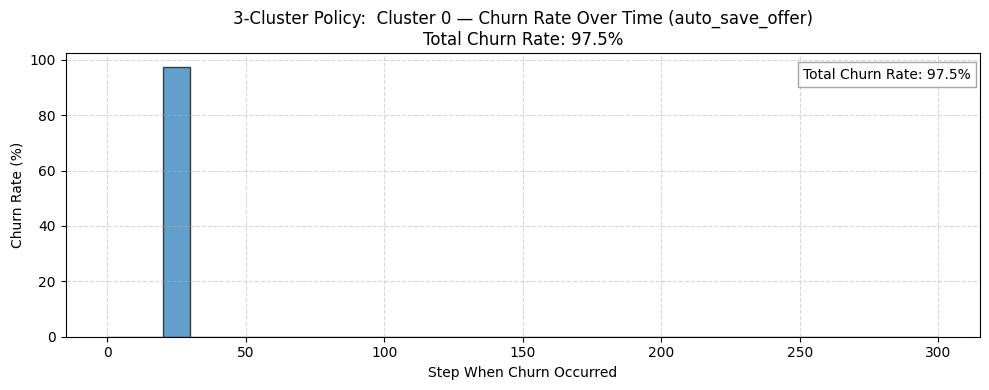

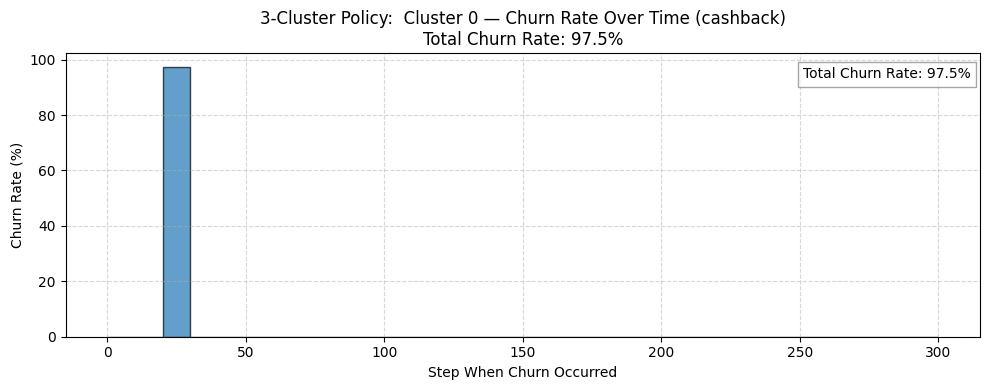

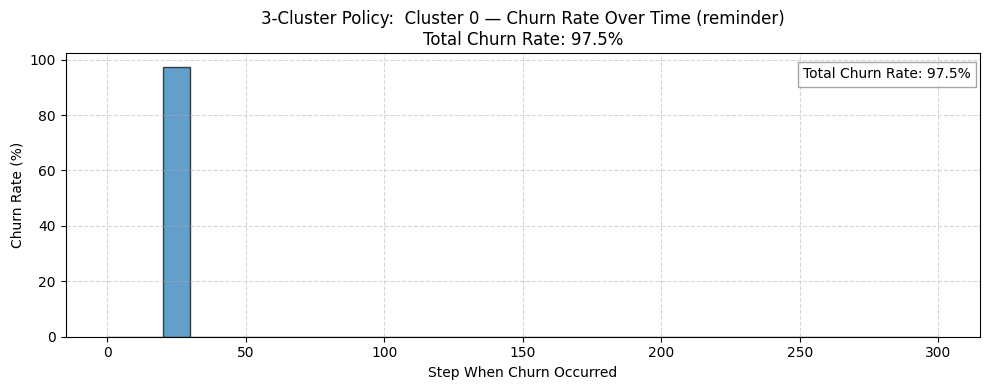

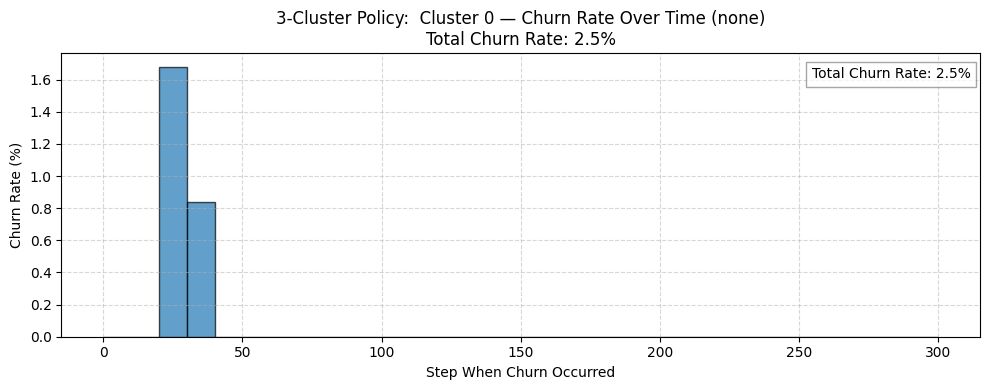

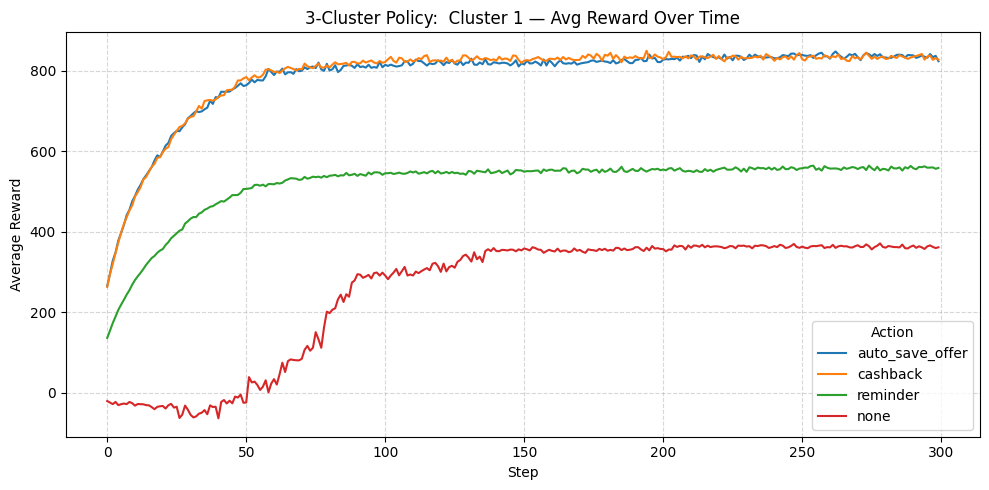

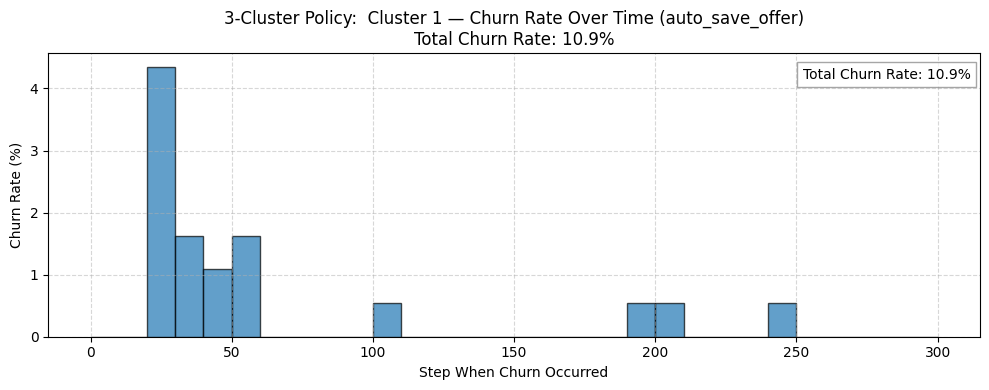

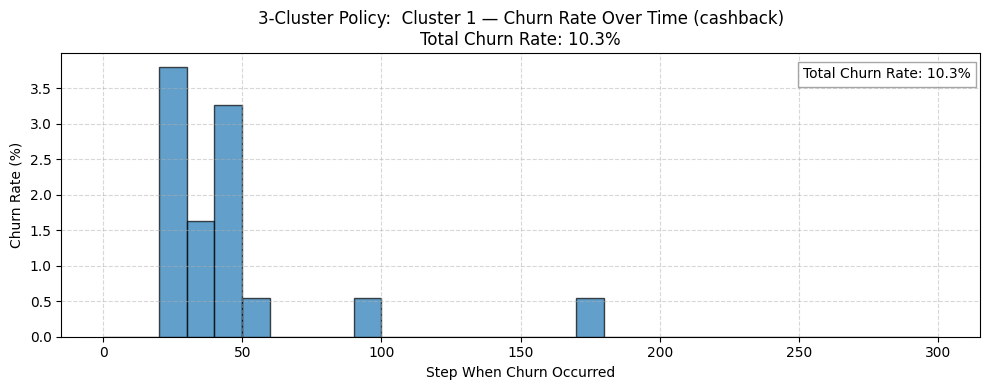

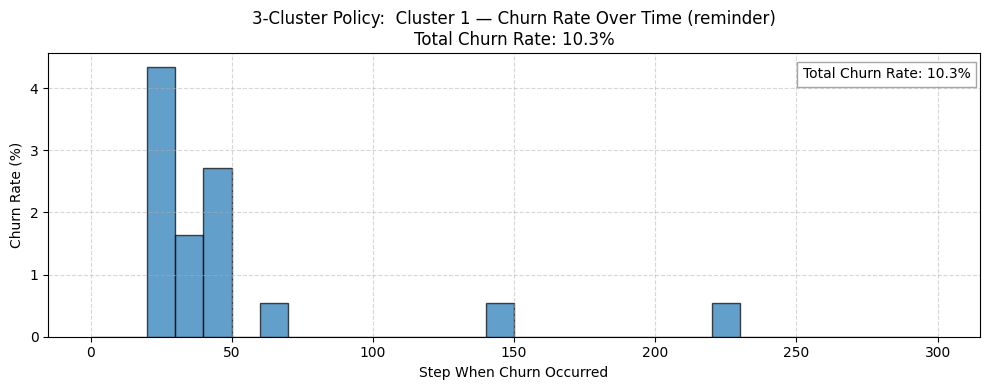

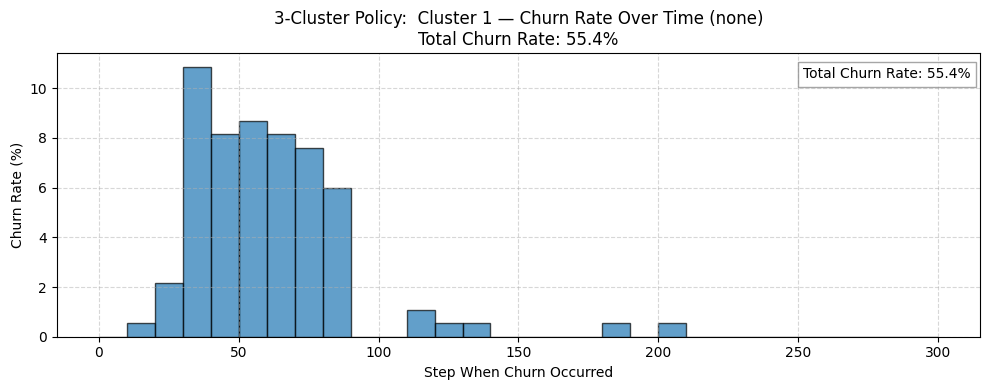

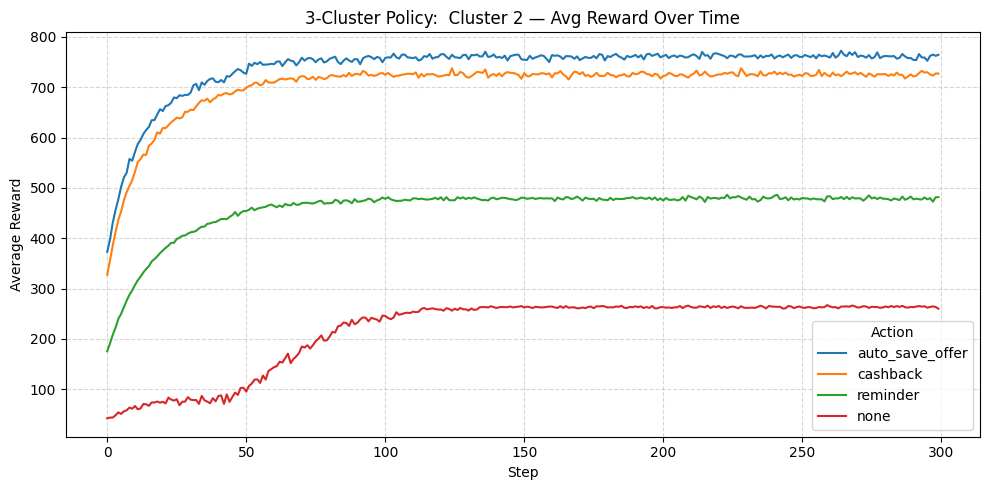

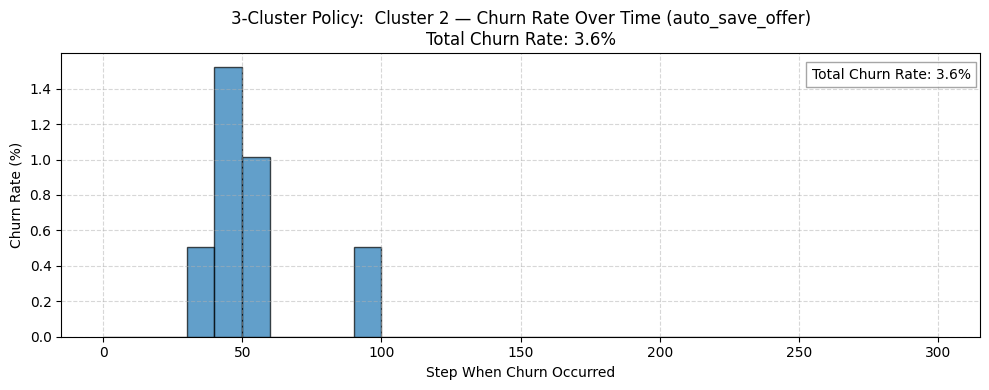

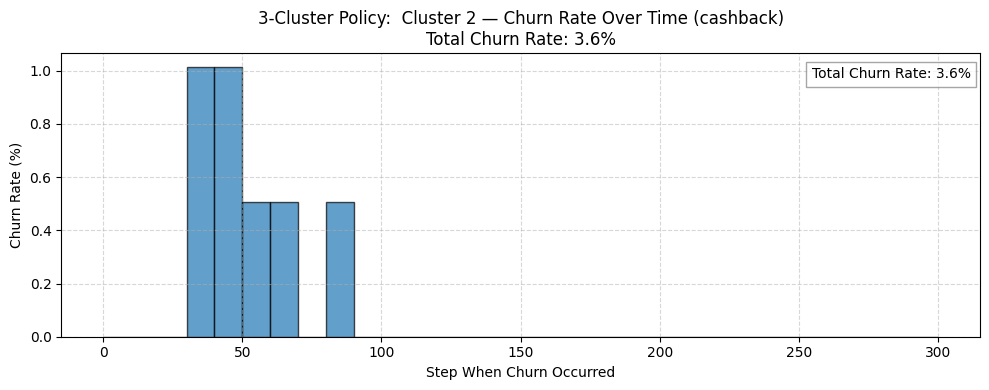

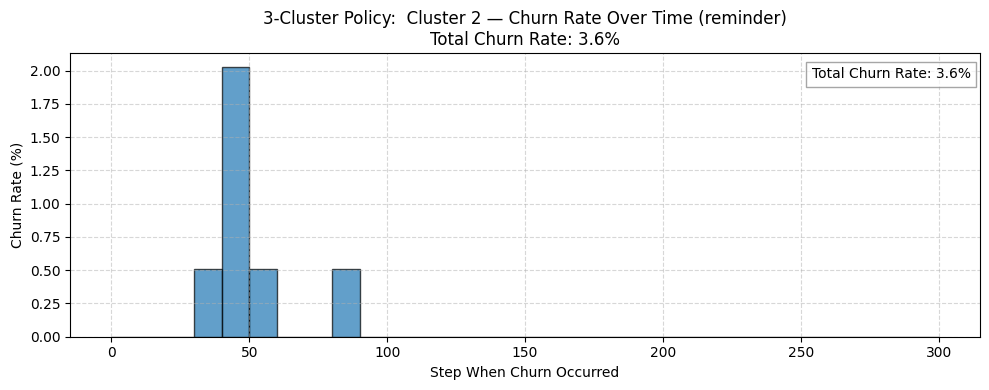

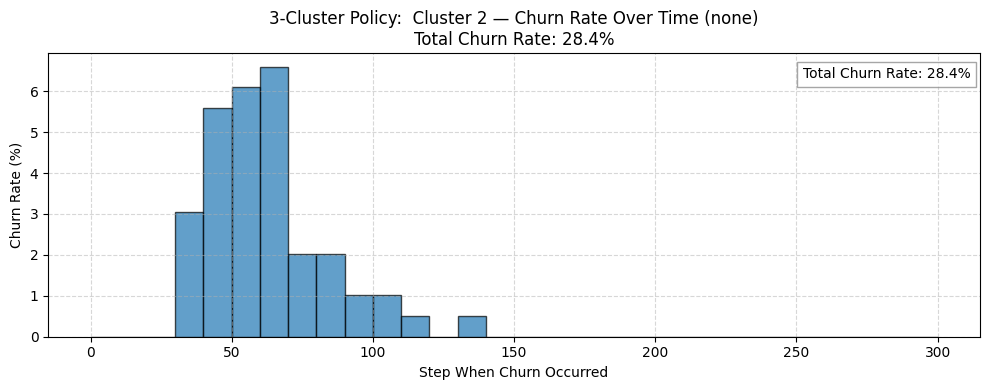

In [ ]:
actions = ['auto_save_offer', 'cashback', 'reminder', 'none']
clusters_to_analyze = [0, 1, 2]
N_STEPS = 300

cluster_action_rewards = {}
cluster_action_churns = {}
cluster_sizes = {}

for cluster in clusters_to_analyze:
    cluster_customers = df_with_clusters_3[df_with_clusters_3['Cluster'] == cluster]['customer_id'].unique()
    cluster_size = len(cluster_customers)
    cluster_sizes[cluster] = cluster_size

    for action in actions:
        rewards_over_time = []
        churn_steps = []

        for customer_id in cluster_customers:
            env = simulator_module.CustomerEnvironment(df_with_clusters_3)
            churned = False

            for step in range(N_STEPS):
                if churned:
                    break
                try:
                    state, reward = env.step(customer_id=customer_id, action=action)
                    rewards_over_time.append((step, reward))

                    if state['churned']:
                        churn_steps.append(step)
                        churned = True
                        break
                except:
                    break

        cluster_action_rewards[(cluster, action)] = rewards_over_time
        cluster_action_churns[(cluster, action)] = churn_steps

for cluster in clusters_to_analyze:
    cluster_size = cluster_sizes[cluster]

    plt.figure(figsize=(10, 5))
    for action in actions:
        data = cluster_action_rewards.get((cluster, action), [])
        if not data:
            continue
        df = pd.DataFrame(data, columns=['step', 'reward'])
        avg = df.groupby('step')['reward'].mean().reset_index()
        plt.plot(avg['step'], avg['reward'], label=action)
    plt.title(f'3-Cluster Policy:  Cluster {cluster} - Avg Reward Over Time')
    plt.xlabel('Step')
    plt.ylabel('Average Reward')
    plt.legend(title='Action')
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

    for action in actions:
        churn_steps = cluster_action_churns.get((cluster, action), [])
        if not churn_steps:
            print(f"[Cluster {cluster} | {action}] no churns.")
            continue

        total_churn_rate = (len(churn_steps) / cluster_size) * 100

        plt.figure(figsize=(10, 4))
        plt.hist(
            churn_steps,
            bins=30,
            range=(0, N_STEPS),
            weights=[100 / cluster_size] * len(churn_steps),
            alpha=0.7,
            edgecolor='black'
        )

        plt.title(
            f'3-Cluster Policy:  Cluster {cluster} - Churn Rate Over Time ({action})\n'
            f'Total Churn Rate: {total_churn_rate:.1f}%'
        )
        plt.xlabel('Step When Churn Occurred')
        plt.ylabel('Churn Rate (%)')
        plt.grid(True, linestyle='--', alpha=0.5)
        plt.text(0.99, 0.95,
                 f'Total Churn Rate: {total_churn_rate:.1f}%',
                 transform=plt.gca().transAxes,
                 fontsize=10,
                 verticalalignment='top',
                 horizontalalignment='right',
                 bbox=dict(facecolor='white', alpha=0.7, edgecolor='gray'))
        plt.tight_layout()
        plt.show()

Cluster 0: none for the first 25 steps, then cashback

Cluster 1: auto_save_offer

Cluster 2: auto_save_offer

Look again at the results the simulator returns for the new policies

Simulating 8-cluster policy...
Simulating 3-cluster policy...
Simulating Random policy...

Policy Comparison Table:
   policy  total_reward  avg_reward_per_customer  churn_rate  num_churned
8-cluster  143271065.81             286542.13162        18.8           94
3-cluster  135005889.20             270011.77840        29.0          145
   Random   91560689.03             183121.37806         5.2           26


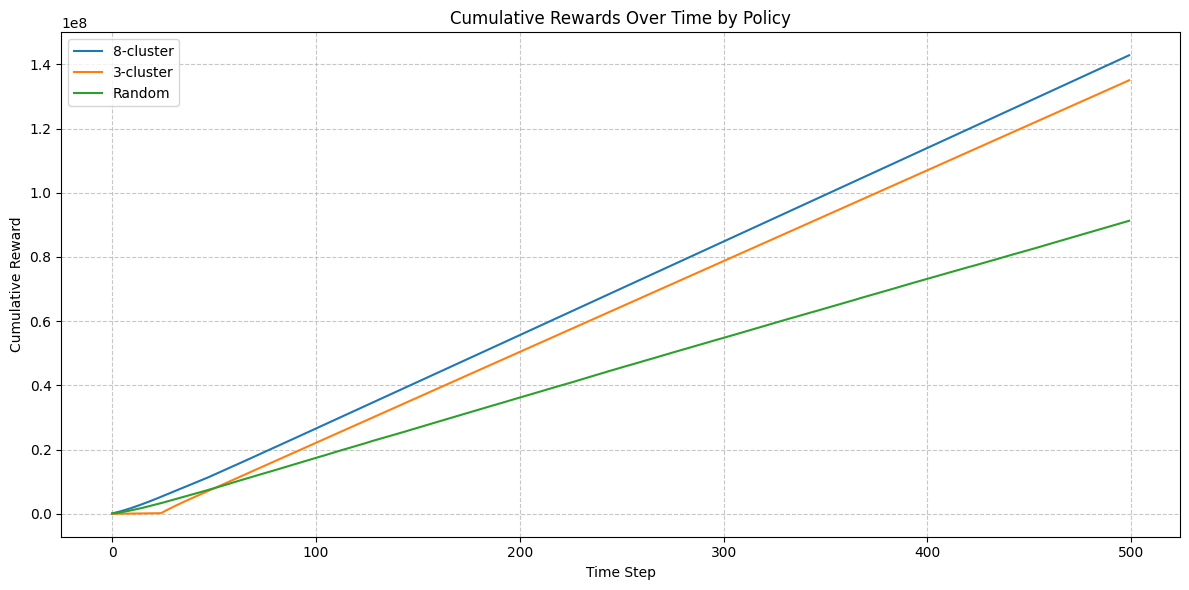

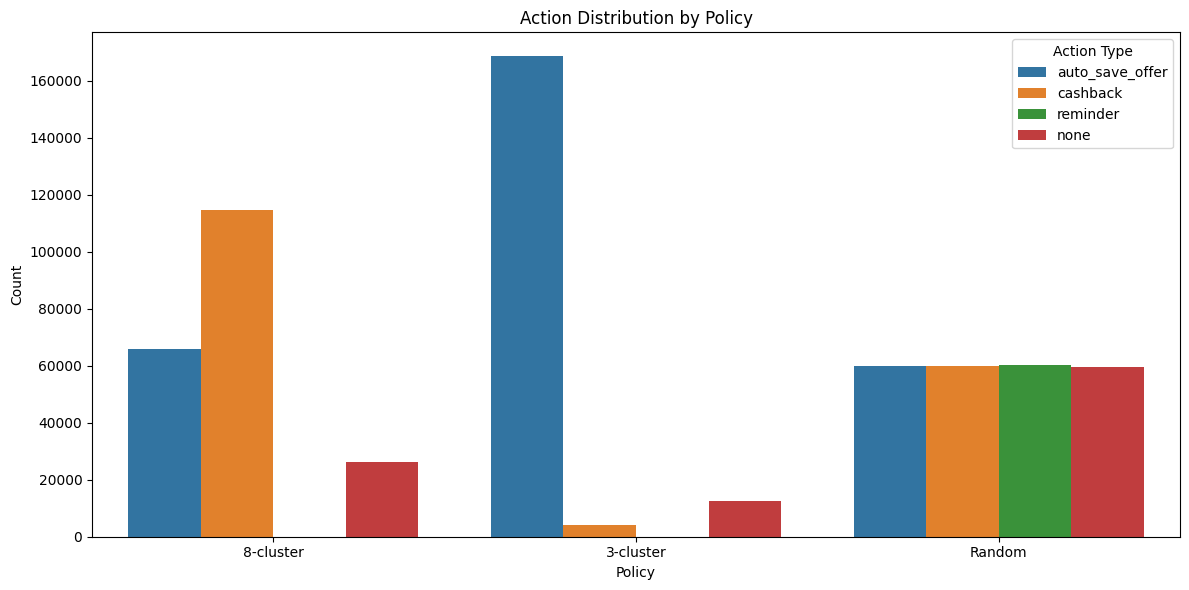

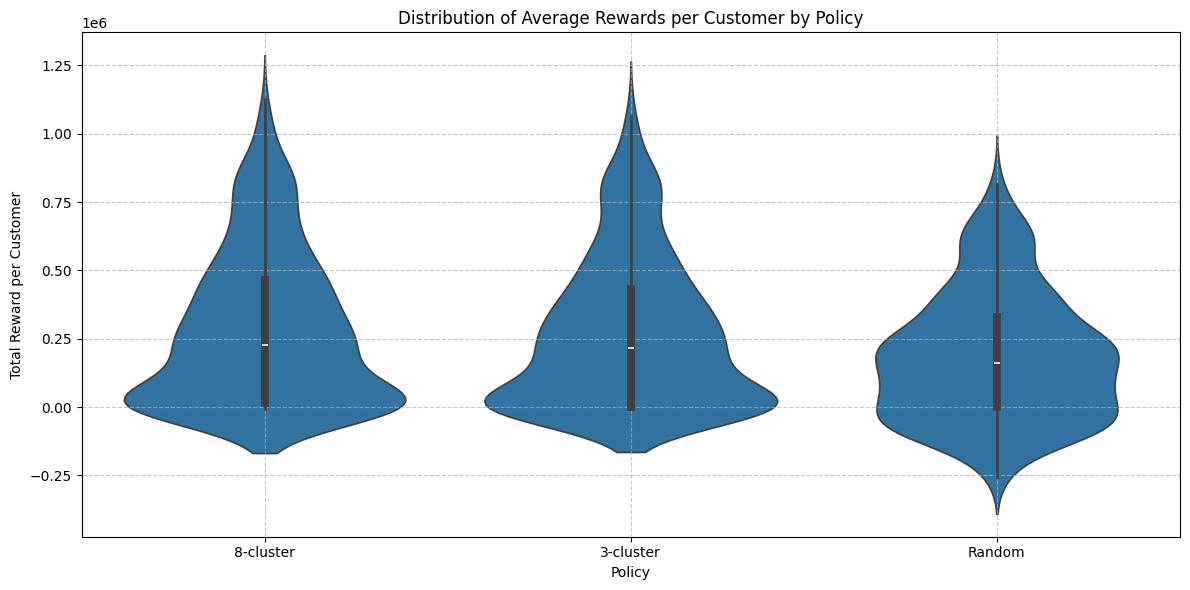

In [ ]:
actions = ['auto_save_offer', 'cashback', 'reminder', 'none']

def random_policy():
    return random.choice(actions)

def get_action(policy_name, customer_id, step):
    if policy_name == '8-cluster':
        cluster = df_with_clusters_8.loc[df_with_clusters_8['customer_id'] == customer_id, 'Cluster'].iloc[0]
        return {
            0: 'cashback',
            1: 'auto_save_offer',
            2: 'none' if step < 25 else 'cashback',
            3: 'cashback',
            4: 'cashback',
            5: 'none',
            6: 'auto_save_offer',
            7: 'cashback'
        }[cluster]

    elif policy_name == '3-cluster':
        cluster = df_with_clusters_3.loc[df_with_clusters_3['customer_id'] == customer_id, 'Cluster'].iloc[0]
        return (
            'none' if step < 25 else 'cashback' if cluster == 0
            else 'auto_save_offer'
        )

    else:
        return random_policy()

def simulate_policy(policy_name, policy_func, num_steps=500):
    total_rewards = []
    churn_counts = []

    customer_ids = df_with_clusters_8['customer_id'].unique()
    for customer_id in customer_ids:
        env = simulator_module.CustomerEnvironment(df_with_clusters_8)
        customer_rewards = []
        churned = False

        for step in range(num_steps):
            if churned:
                break
            try:
                action = get_action(policy_name, customer_id, step)
                state, reward = env.step(customer_id=customer_id, action=action)
                customer_rewards.append(reward)

                if state['churned']:
                    churned = True
                    break
            except Exception as e:
                print(f"Error for customer {customer_id}, step {step}: {e}")
                break

        total_rewards.append(sum(customer_rewards))
        churn_counts.append(1 if churned else 0)

    return {
        'policy': policy_name,
        'total_reward': sum(total_rewards),
        'avg_reward_per_customer': np.mean(total_rewards) if total_rewards else 0,
        'churn_rate': np.mean(churn_counts) * 100 if churn_counts else 0,
        'num_churned': sum(churn_counts),
        'rewards_per_customer': total_rewards
    }

def collect_visualization_data(policy_name, policy_func, num_steps=500):
    action_counts = {action: 0 for action in actions}
    cumulative_rewards_over_time = np.zeros(num_steps)
    customer_ids = df_with_clusters_8['customer_id'].unique()

    for customer_id in customer_ids:
        env = simulator_module.CustomerEnvironment(df_with_clusters_8)
        churned = False

        for step in range(num_steps):
            if churned:
                break
            try:
                action = get_action(policy_name, customer_id, step)
                action_counts[action] += 1
                state, reward = env.step(customer_id=customer_id, action=action)
                if step < num_steps:
                    cumulative_rewards_over_time[step] += reward
                if state['churned']:
                    churned = True
            except:
                break

    cumulative_sum_rewards = np.cumsum(cumulative_rewards_over_time)
    return {
        'action_counts': action_counts,
        'cumulative_rewards': cumulative_sum_rewards
    }

policies = [
    ('8-cluster', lambda: None),
    ('3-cluster', lambda: None),
    ('Random', random_policy)
]

results = []
rewards_distribution_data = {}

for policy_name, policy_func in policies:
    print(f"Simulating {policy_name} policy...")
    result = simulate_policy(policy_name, policy_func, num_steps=500)
    results.append(result)
    rewards_distribution_data[policy_name] = result['rewards_per_customer']

results_df = pd.DataFrame(results)

print("\nPolicy Comparison Table:")
print(results_df[['policy', 'total_reward', 'avg_reward_per_customer', 'churn_rate', 'num_churned']].to_string(index=False))

cumulative_rewards_data = {}
action_distribution_data = {}

for policy_name, policy_func in policies:
    viz_data = collect_visualization_data(policy_name, policy_func, num_steps=500)
    cumulative_rewards_data[policy_name] = viz_data['cumulative_rewards']
    action_distribution_data[policy_name] = viz_data['action_counts']

plt.figure(figsize=(12, 6))
for policy_name, rewards in cumulative_rewards_data.items():
    plt.plot(range(len(rewards)), rewards, label=policy_name)
plt.title('Cumulative Rewards Over Time by Policy')
plt.xlabel('Time Step')
plt.ylabel('Cumulative Reward')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 6))
action_data = []
for policy_name, action_counts in action_distribution_data.items():
    for action, count in action_counts.items():
        action_data.append({
            'Policy': policy_name,
            'Action': action,
            'Count': count
        })
action_df = pd.DataFrame(action_data)
sns.barplot(x='Policy', y='Count', hue='Action', data=action_df)
plt.title('Action Distribution by Policy')
plt.xlabel('Policy')
plt.ylabel('Count')
plt.legend(title='Action Type')
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 6))
rewards_data = []
for policy_name, rewards in rewards_distribution_data.items():
    for reward in rewards:
        rewards_data.append({
            'Policy': policy_name,
            'Reward': reward
        })
rewards_df = pd.DataFrame(rewards_data)
sns.violinplot(x='Policy', y='Reward', data=rewards_df)
plt.title('Distribution of Average Rewards per Customer by Policy')
plt.xlabel('Policy')
plt.ylabel('Total Reward per Customer')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

Although total reward grew by about 10,000,000, the churn rate also grew about three times:

![image.png](attachment:image.png)

Again we can do a segment analysis and see which clusters have a high churn rate

In [ ]:
best_policy_name = results_df.loc[results_df['total_reward'].idxmax(), 'policy']
print(f"The best performing policy based on total reward is: {best_policy_name}")

def analyze_policy_by_segments(policy_name):
    if policy_name == '8-cluster':
        df_with_clusters = df_with_clusters_8
        cluster_actions = cluster_8_actions
        num_clusters = 8
    elif policy_name == '3-cluster':
        df_with_clusters = df_with_clusters_3
        cluster_actions = cluster_3_actions
        num_clusters = 3
    else:
        print("Random policy doesn't have well-defined segments. Using 8-cluster segmentation for analysis.")
        df_with_clusters = df_with_clusters_8
        cluster_actions = {i: 'random' for i in range(8)}
        num_clusters = 8

    segment_results = []
    segment_rewards_over_time = {}
    segment_churn_over_time = {}

    for cluster in range(num_clusters):
        cluster_customers = df_with_clusters[df_with_clusters['Cluster'] == cluster]['customer_id'].unique()

        if len(cluster_customers) == 0:
            continue

        if callable(cluster_actions.get(cluster, None)):
            action = "Random choice: none/reminder"
        else:
            action = cluster_actions.get(cluster, "random")

        total_reward = 0
        churn_count = 0
        customer_rewards = []
        all_rewards_over_time = []
        churns_over_time = []

        for customer_id in cluster_customers:
            env = simulator_module.CustomerEnvironment(df_with_clusters)
            rewards = []
            churned = False

            for step in range(300):
                if policy_name == '8-cluster':
                    act = cluster_8_actions[cluster]
                elif policy_name == '3-cluster':
                    act = cluster_3_actions[cluster]() if callable(cluster_3_actions[cluster]) else cluster_3_actions[cluster]
                else:
                    act = random_policy()

                try:
                    state, reward = env.step(customer_id=customer_id, action=act)
                    rewards.append(reward)

                    if state['churned']:
                        churned = True
                        churns_over_time.append(step)
                        break
                except Exception as e:
                    break

            customer_total_reward = sum(rewards)
            total_reward += customer_total_reward
            customer_rewards.append(customer_total_reward)
            all_rewards_over_time.extend([(step, r) for step, r in enumerate(rewards)])
            churn_count += 1 if churned else 0

        segment_size = len(cluster_customers)
        avg_reward = total_reward / segment_size if segment_size > 0 else 0
        churn_rate = (churn_count / segment_size) * 100 if segment_size > 0 else 0

        segment_results.append({
            'Cluster': cluster,
            'Offer': action,
            'Size': segment_size,
            'Total Reward': total_reward,
            'Average Reward': avg_reward,
            'Churn Rate': churn_rate,
            'Churn Count': churn_count
        })

        segment_rewards_over_time[cluster] = all_rewards_over_time
        segment_churn_over_time[cluster] = churns_over_time

    return pd.DataFrame(segment_results), segment_rewards_over_time, segment_churn_over_time

segment_analysis, rewards_over_time, churns_over_time = analyze_policy_by_segments(best_policy_name)

print("\nSegment Analysis for Policy with Highest Total Reward:")
print(segment_analysis[['Cluster', 'Offer', 'Average Reward', 'Churn Rate']])

The best performing policy based on total reward is: 8-cluster

Segment Analysis for Policy with Highest Total Reward:
   Cluster            Offer  Average Reward  Churn Rate
0        0  auto_save_offer   207438.298384    0.000000
1        1         cashback   234577.987869    0.000000
2        2             none    14770.437324    2.816901
3        3  auto_save_offer   116208.862824    3.529412
4        4         reminder    25989.155641   38.461538
5        5             none     7781.848776    0.000000
6        6         cashback   427487.755070    0.000000
7        7         reminder    20350.843200   28.000000


Now we can try to build a more effective policy with Reinforcement Learning.

We use different methods to group the continuous variables. First: find the optimal number of clusters within each variable and create the groups of that variable from these clusters, while watching the distribution so that no group comes out too small.

Before grouping the variables we have to set aside the test data, which takes no part in creating the optimal bins, in order to avoid data leakage.

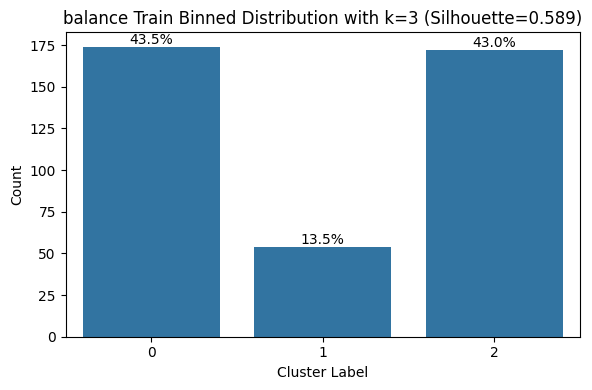

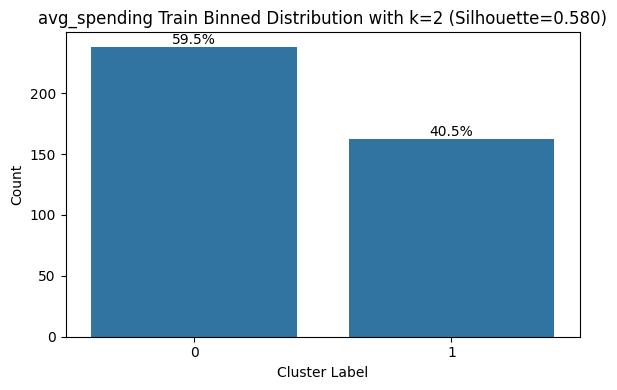

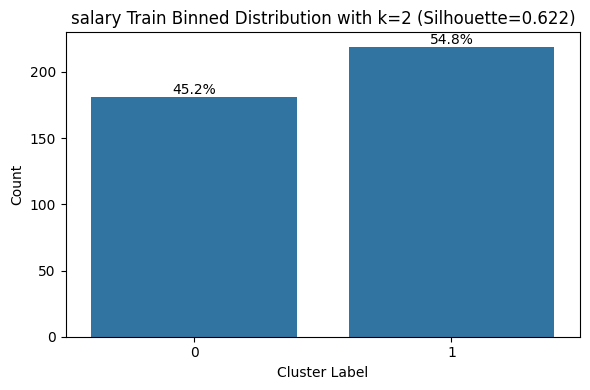

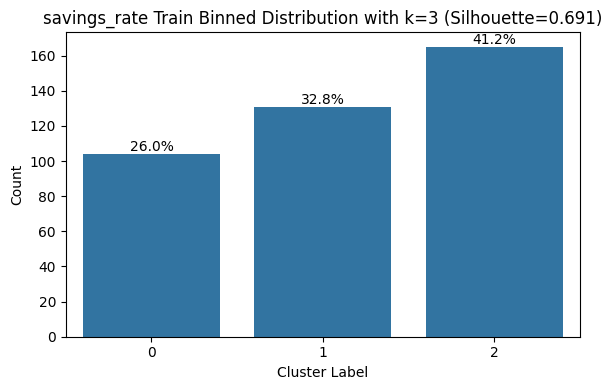

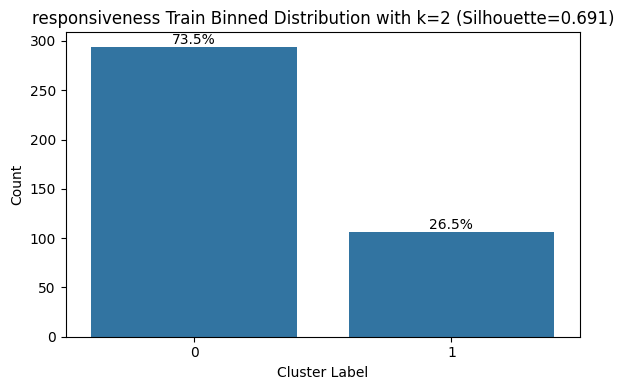

Binning info per feature and cluster edges (train data):

Feature: balance
Optimal bins: 3, Silhouette Score: 0.5886
Cluster edges:
 Bin 0: -inf to 8415.9522
 Bin 1: 8415.9522 to 13115.3260
 Bin 2: 13115.3260 to inf

Feature: avg_spending
Optimal bins: 2, Silhouette Score: 0.5804
Cluster edges:
 Bin 0: -inf to 3686.0110
 Bin 1: 3686.0110 to inf

Feature: salary
Optimal bins: 2, Silhouette Score: 0.6222
Cluster edges:
 Bin 0: -inf to 4977.4209
 Bin 1: 4977.4209 to inf

Feature: savings_rate
Optimal bins: 3, Silhouette Score: 0.6908
Cluster edges:
 Bin 0: -inf to 0.0222
 Bin 1: 0.0222 to 0.0398
 Bin 2: 0.0398 to inf

Feature: responsiveness
Optimal bins: 2, Silhouette Score: 0.6912
Cluster edges:
 Bin 0: -inf to 0.4697
 Bin 1: 0.4697 to inf


In [ ]:
df_full = pd.read_csv('ds_assignment_customer_data.csv')
train_df, test_df = train_test_split(df_full, test_size=100, random_state=42, shuffle=True)
features = train_df.columns.tolist()
features.remove('customer_id')

def cluster_feature_optimal_k(train_series, k_range=range(2,9), random_state=42):
    values = train_series.values.reshape(-1,1)
    best_k = None
    best_score = -1
    best_labels = None
    best_kmeans = None
    for k in k_range:
        kmeans = KMeans(n_clusters=k, random_state=random_state)
        labels = kmeans.fit_predict(values)
        if len(np.unique(labels)) == 1:
            continue
        score = silhouette_score(values, labels)
        if score > best_score:
            best_score = score
            best_k = k
            best_labels = labels
            best_kmeans = kmeans
    return best_k, best_labels, best_score, best_kmeans

binned_train = pd.DataFrame({'customer_id': train_df['customer_id']})
bin_info = {}

for feat in features:
    k, labels, score, kmeans = cluster_feature_optimal_k(train_df[feat])
    binned_train[feat+'_bin'] = labels
    bin_info[feat] = {'best_k': k, 'silhouette': score, 'kmeans': kmeans}

    plt.figure(figsize=(6,4))
    ax = sns.countplot(x=labels)
    total = len(labels)
    for p in ax.patches:
        count = p.get_height()
        percentage = count / total * 100
        ax.annotate(f'{percentage:.1f}%', (p.get_x() + p.get_width() / 2, count),
                    ha='center', va='bottom')
    plt.title(f'{feat} Train Binned Distribution with k={k} (Silhouette={score:.3f})')
    plt.xlabel('Cluster Label')
    plt.ylabel('Count')
    plt.tight_layout()
    plt.show()

print("Binning info per feature and cluster edges (train data):")

for feat, info in bin_info.items():
    centers = np.sort(info['kmeans'].cluster_centers_.flatten())
    edges = [(centers[i] + centers[i+1]) / 2 for i in range(len(centers)-1)]
    edges = [-np.inf] + edges + [np.inf]
    print(f"\nFeature: {feat}")
    print(f"Optimal bins: {info['best_k']}, Silhouette Score: {info['silhouette']:.4f}")
    print("Cluster edges:")
    for i in range(len(edges)-1):
        low = edges[i]
        high = edges[i+1]
        low_str = '-inf' if low == -np.inf else f"{low:.4f}"
        high_str = 'inf' if high == np.inf else f"{high:.4f}"
        print(f" Bin {i}: {low_str} to {high_str}")

binned_test = pd.DataFrame({'customer_id': test_df['customer_id']})

for feat in features:
    kmeans = bin_info[feat]['kmeans']
    test_values = test_df[feat].values.reshape(-1,1)
    test_labels = kmeans.predict(test_values)
    binned_test[feat+'_bin'] = test_labels

Train the model using this discretization

Use cross-validation to reduce overfitting and tune the parameters to get a stronger model

In [ ]:
df_clusters_train = binned_train.copy()
df_clusters_test = binned_test.copy()

# Setup simulator (unchanged)
spec = importlib.util.spec_from_file_location("simulator", "simulator.cpython-39.pyc")
simulator_module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(simulator_module)
CustomerEnvironment = simulator_module.CustomerEnvironment

# Prepare state mappings for train and test sets (static features for initial segmentation)
features_bins = [c for c in df_clusters_train.columns if c.endswith('_bin')]

state_map_train = {
    row['customer_id']: tuple(row[features_bins])
    for _, row in df_clusters_train.iterrows()
}

state_map_test = {
    row['customer_id']: tuple(row[features_bins])
    for _, row in df_clusters_test.iterrows()
}

# Prepare train and test customer IDs
train_ids = list(state_map_train.keys())
test_ids = list(state_map_test.keys())

actions = ['auto_save_offer','cashback','reminder','none']
action_to_idx = {a:i for i,a in enumerate(actions)}
idx_to_action = {i:a for a,i in action_to_idx.items()}

def ensure_state_in_Q(Q, state, n_actions):
    if state not in Q:
        Q[state] = np.zeros(n_actions)

def discretize_dynamic_value(value, thresholds):
    """Discretize a continuous value into bins based on thresholds"""
    if np.isnan(value) or value is None:
        return 0  # Default bin for invalid values

    for i, threshold in enumerate(thresholds):
        if value <= threshold:
            return i
    return len(thresholds)  # Last bin for values above all thresholds

def get_dynamic_state(sim_state, static_state):
    """
    Convert simulator state to a state representation that combines
    static customer segment with dynamic state bins
    """
    balance = sim_state.get('balance', 0)
    savings = sim_state.get('savings', 0)
    loyalty = sim_state.get('loyalty', 1.0)

    balance_bin = discretize_dynamic_value(balance, [5000, 10000, 20000, 50000])
    savings_bin = discretize_dynamic_value(savings, [1000, 5000, 10000, 20000])
    loyalty_bin = discretize_dynamic_value(loyalty, [0.3, 0.6, 0.8, 1.0])

    dynamic_state = (balance_bin, savings_bin, loyalty_bin)
    combined_state = static_state + dynamic_state

    return combined_state

# Define param grid and sample params
param_grid = {
    'alpha':        [0.1, 0.01],
    'gamma':        [0.9, 0.99],
    'epsilon_start':[1.0],
    'epsilon_decay':[0.995, 0.99],
    'epsilon_min':  [0.1]
}
all_params = list(ParameterGrid(param_grid))
np.random.seed(42)
sampled_params = list(np.random.choice(all_params, size=min(6,len(all_params)), replace=False))

kf = KFold(n_splits=3, shuffle=True, random_state=42)

cv_records = []
for params in sampled_params:
    fold_metrics = []
    for train_idx, val_idx in kf.split(train_ids):
        cv_train = [train_ids[i] for i in train_idx]
        cv_val   = [train_ids[i] for i in val_idx]

        Q = {}
        eps = params['epsilon_start']

        for epoch in range(30):
            for cid in cv_train:
                env = CustomerEnvironment(df_full)

                # Get initial state and reward
                initial_sim_state, initial_reward = env.step(customer_id=cid, action='none')
                static_customer_state = state_map_train[cid]
                current_state = get_dynamic_state(initial_sim_state, static_customer_state)

                churned = False
                steps = 0
                total_r = initial_reward  # Include initial reward

                while not churned and steps < 500:
                    s = current_state
                    ensure_state_in_Q(Q, s, len(actions))

                    # Choose action (epsilon-greedy)
                    if random.random() < eps:
                        a_idx = random.randrange(len(actions))
                    else:
                        a_idx = int(np.argmax(Q[s]))
                    a = idx_to_action[a_idx]

                    # Take action and get next state and reward
                    next_sim_state, reward = env.step(customer_id=cid, action=a)
                    total_r += reward  # Accumulate reward
                    churned = next_sim_state.get('churned', False)

                    # Get next state representation
                    if not churned:
                        next_state = get_dynamic_state(next_sim_state, static_customer_state)
                        ensure_state_in_Q(Q, next_state, len(actions))
                        best_next_q = np.max(Q[next_state])
                    else:
                        best_next_q = 0.0

                    # Q-learning update
                    Q[s][a_idx] += params['alpha'] * (
                        reward + params['gamma'] * best_next_q - Q[s][a_idx]
                    )

                    if not churned:
                        current_state = next_state

                    steps += 1

            eps = max(params['epsilon_min'], eps * params['epsilon_decay'])

        # Validation phase
        rews, churns = [], []
        for cid in cv_val:
            env = CustomerEnvironment(df_full)

            initial_sim_state, initial_reward = env.step(customer_id=cid, action='none')
            static_customer_state = state_map_train[cid]
            current_state = get_dynamic_state(initial_sim_state, static_customer_state)

            churned = False
            total_r = initial_reward
            steps = 0

            while not churned and steps < 500:
                s = current_state
                ensure_state_in_Q(Q, s, len(actions))

                a_idx = int(np.argmax(Q[s]))
                a = idx_to_action[a_idx]

                next_sim_state, r = env.step(customer_id=cid, action=a)
                total_r += r
                churned = next_sim_state.get('churned', False)

                if not churned:
                    current_state = get_dynamic_state(next_sim_state, static_customer_state)

                steps += 1

            rews.append(total_r)
            churns.append(1 if churned else 0)

        fold_metrics.append((np.mean(rews), np.mean(churns)))

    cv_records.append({
        **params,
        'cv_avg_reward': np.mean([m[0] for m in fold_metrics]),
        'cv_churn_rate': np.mean([m[1] for m in fold_metrics])
    })

best = sorted(cv_records, key=lambda x:(-x['cv_avg_reward'], x['cv_churn_rate']))[0]
print("Best hyperparams (cluster):", best)

# Final train on full training set
Q_final = {}
eps = best['epsilon_start']

for epoch in range(30):
    for cid in train_ids:
        env = CustomerEnvironment(df_full)

        # Get initial state and reward
        initial_sim_state, initial_reward = env.step(customer_id=cid, action='none')
        static_customer_state = state_map_train[cid]
        current_state = get_dynamic_state(initial_sim_state, static_customer_state)

        churned = False
        steps = 0
        total_r = initial_reward  # Include initial reward

        while not churned and steps < 500:
            s = current_state
            ensure_state_in_Q(Q_final, s, len(actions))

            if random.random() < eps:
                a_idx = random.randrange(len(actions))
            else:
                a_idx = int(np.argmax(Q_final[s]))
            a = idx_to_action[a_idx]

            next_sim_state, reward = env.step(customer_id=cid, action=a)
            total_r += reward  # Accumulate reward
            churned = next_sim_state.get('churned', False)

            if not churned:
                next_state = get_dynamic_state(next_sim_state, static_customer_state)
                ensure_state_in_Q(Q_final, next_state, len(actions))
                best_next_q = np.max(Q_final[next_state])
            else:
                best_next_q = 0.0

            Q_final[s][a_idx] += best['alpha'] * (
                reward + best['gamma'] * best_next_q - Q_final[s][a_idx]
            )

            if not churned:
                current_state = next_state

            steps += 1

    eps = max(best['epsilon_min'], eps * best['epsilon_decay'])

def evaluate(ids, state_map, Q, df_full):
    """Corrected evaluation function with proper state handling"""
    tots, churns = [], []
    for cid in ids:
        env = CustomerEnvironment(df_full)

        initial_sim_state, initial_reward = env.step(customer_id=cid, action='none')
        static_customer_state = state_map[cid]
        current_state = get_dynamic_state(initial_sim_state, static_customer_state)

        churned = False
        total_r = initial_reward
        steps = 0

        while not churned and steps < 500:
            s = current_state
            ensure_state_in_Q(Q, s, len(actions))

            a_idx = int(np.argmax(Q[s]))
            a = idx_to_action[a_idx]

            next_sim_state, r = env.step(customer_id=cid, action=a)
            total_r += r
            churned = next_sim_state.get('churned', False)

            if not churned:
                current_state = get_dynamic_state(next_sim_state, static_customer_state)

            steps += 1

        tots.append(total_r)
        churns.append(1 if churned else 0)

    return sum(tots), np.mean(tots), np.mean(churns)*100

# Evaluate with corrected function
train_m = evaluate(train_ids, state_map_train, Q_final, df_full)
test_m = evaluate(test_ids, state_map_test, Q_final, df_full)

print(f"Cluster-based RL"
      f" Train Total:{train_m[0]:.1f}, Avg:{train_m[1]:.1f}, Churn%:{train_m[2]:.1f} | "
      f" Test Total:{test_m[0]:.1f}, Avg:{test_m[1]:.1f}, Churn%:{test_m[2]:.1f}")

Best hyperparams (cluster): {'alpha': 0.01, 'epsilon_decay': 0.995, 'epsilon_min': 0.1, 'epsilon_start': 1.0, 'gamma': 0.9, 'cv_avg_reward': np.float64(283460.2945552314), 'cv_churn_rate': np.float64(0.0674634347061684)}
Cluster-based RL Train Total:114184360.2, Avg:285460.9, Churn%:6.0 |  Test Total:29708287.9, Avg:297082.9, Churn%:9.0


The test set results are slightly worse than the training set results, which is logical. At this stage we can assume the model should not have an overfitting problem.

Second: as a discretization method we can use percentiles and split the data into four groups of equal proportion

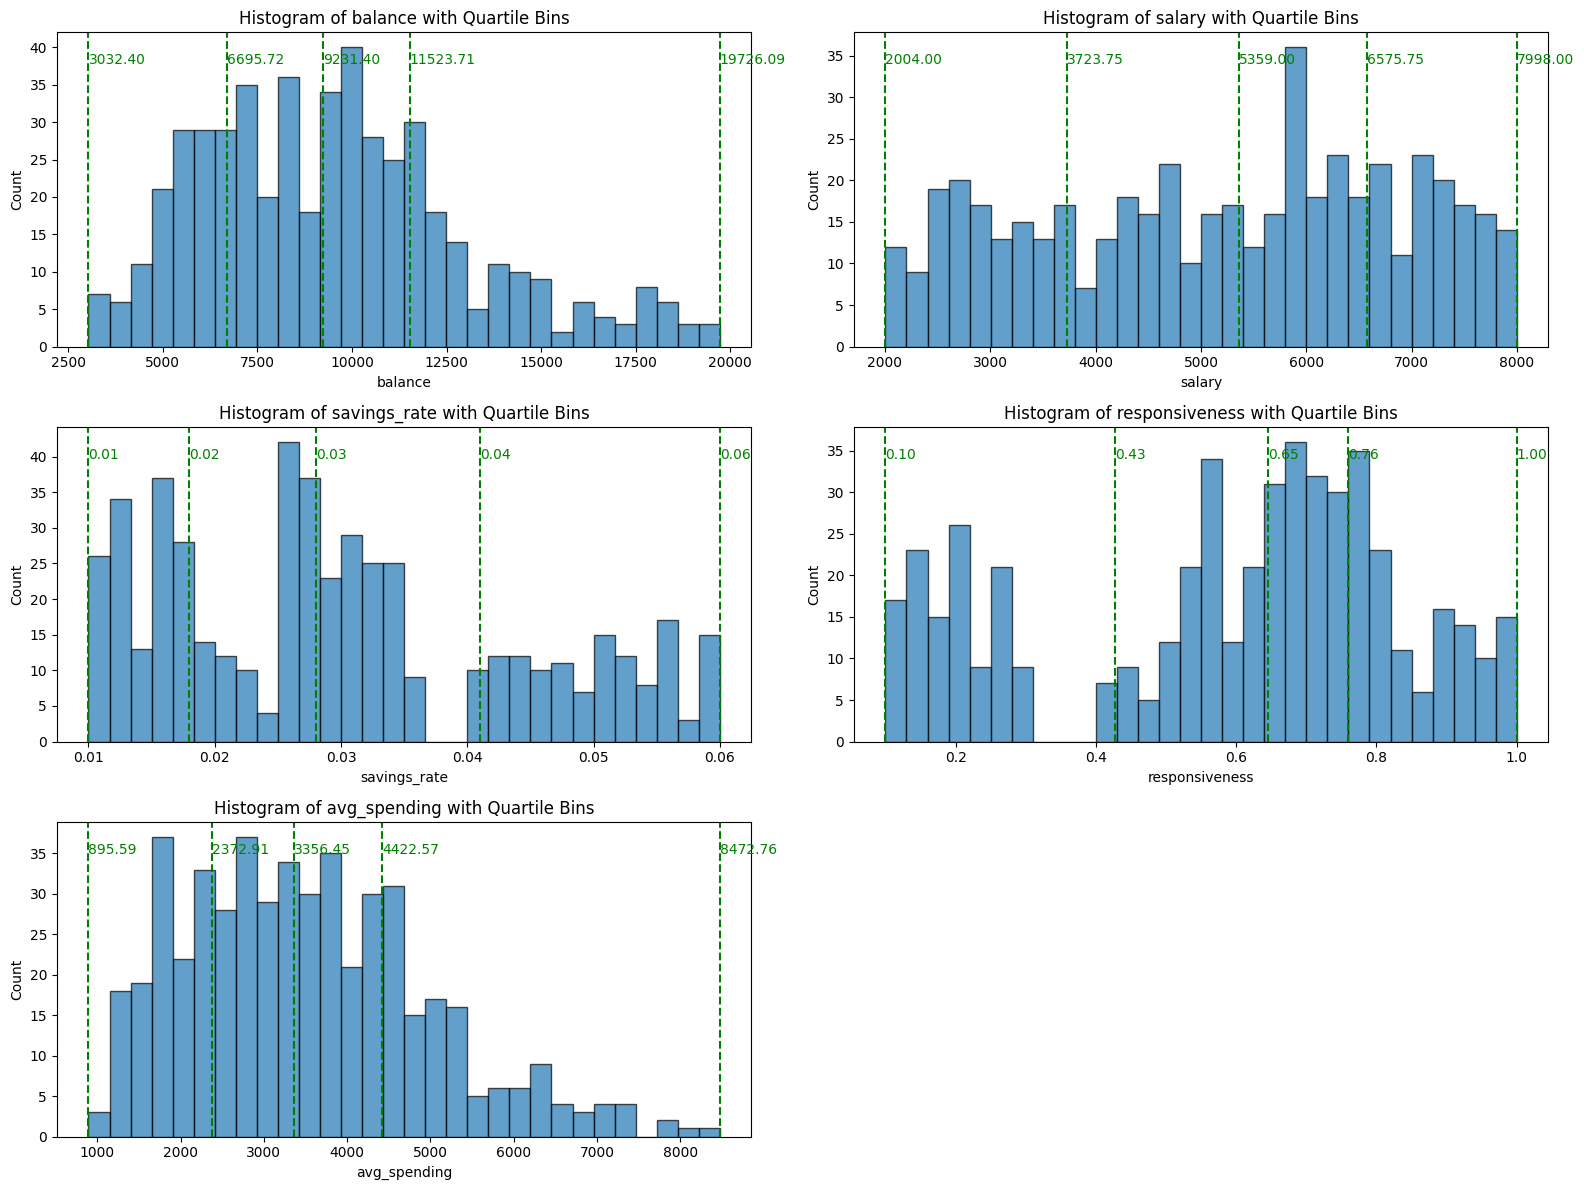

In [ ]:
customer_df = pd.read_csv('ds_assignment_customer_data.csv')
features = ['balance', 'salary', 'savings_rate', 'responsiveness', 'avg_spending']

plt.figure(figsize=(16, 12))

for i, feature in enumerate(features, 1):
    data = customer_df[feature]
    q0 = data.min()
    q25 = data.quantile(0.25)
    q50 = data.quantile(0.50)
    q75 = data.quantile(0.75)
    q100 = data.max()

    bins = [q0, q25, q50, q75, q100]

    plt.subplot(3, 2, i)
    plt.hist(data, bins=30, edgecolor='black', alpha=0.7)
    plt.title(f"Histogram of {feature} with Quartile Bins")
    plt.xlabel(feature)
    plt.ylabel("Count")

    for b in bins:
        plt.axvline(b, color='green', linestyle='--')

    plt.text(q0, plt.ylim()[1]*0.9, f"{q0:.2f}", color='green')
    plt.text(q25, plt.ylim()[1]*0.9, f"{q25:.2f}", color='green')
    plt.text(q50, plt.ylim()[1]*0.9, f"{q50:.2f}", color='green')
    plt.text(q75, plt.ylim()[1]*0.9, f"{q75:.2f}", color='green')
    plt.text(q100, plt.ylim()[1]*0.9, f"{q100:.2f}", color='green')

plt.tight_layout()
plt.show()

Train the RL model again. We used the same train/test set so that the models can be compared with each other

In [ ]:
features = ['balance', 'salary', 'savings_rate', 'responsiveness', 'avg_spending']

# Compute train quantiles per feature and bin train data accordingly
train_binned = train_df[['customer_id']].copy()
quantile_edges = {}

for feat in features:
    qs = train_df[feat].quantile([0, 0.25, 0.5, 0.75, 1.0]).values
    quantile_edges[feat] = qs
    train_binned[f'{feat}_bin'] = np.digitize(train_df[feat], bins=qs[1:-1], right=True)

# Bin test data using train quantile edges
test_binned = test_df[['customer_id']].copy()
for feat in features:
    qs = quantile_edges[feat]
    test_binned[f'{feat}_bin'] = np.digitize(test_df[feat], bins=qs[1:-1], right=True)

features_bin = [f'{feat}_bin' for feat in features]

# Setup simulator
import importlib.util
spec = importlib.util.spec_from_file_location("simulator", "simulator.cpython-39.pyc")
simulator_module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(simulator_module)
CustomerEnvironment = simulator_module.CustomerEnvironment

# Prepare state mappings for train and test sets
state_map_train = {
    row['customer_id']: tuple(row[features_bin])
    for _, row in train_binned.iterrows()
}

state_map_test = {
    row['customer_id']: tuple(row[features_bin])
    for _, row in test_binned.iterrows()
}

train_ids = list(state_map_train.keys())
test_ids = list(state_map_test.keys())

actions = ['auto_save_offer','cashback','reminder','none']
action_to_idx = {a:i for i,a in enumerate(actions)}
idx_to_action = {i:a for a,i in action_to_idx.items()}

def ensure_state_in_Q(Q, state, n_actions):
    if state not in Q:
        Q[state] = np.zeros(n_actions)

param_grid = {
    'alpha':        [0.1, 0.01],
    'gamma':        [0.9, 0.99],
    'epsilon_start':[1.0],
    'epsilon_decay':[0.995, 0.99],
    'epsilon_min':  [0.1]
}
all_params = list(ParameterGrid(param_grid))
np.random.seed(42)
sampled_params = list(np.random.choice(all_params, size=min(6,len(all_params)), replace=False))

kf = KFold(n_splits=3, shuffle=True, random_state=42)

cv_records = []
for params in sampled_params:
    fold_metrics = []
    for train_idx, val_idx in kf.split(train_ids):
        cv_train = [train_ids[i] for i in train_idx]
        cv_val   = [train_ids[i] for i in val_idx]

        Q = {}
        eps = params['epsilon_start']

        for epoch in range(30):
            for cid in cv_train:
                env = CustomerEnvironment(train_df)
                # Get initial state and reward
                initial_sim_state, initial_reward = env.step(customer_id=cid, action='none')
                s = state_map_train[cid]
                churned = False
                steps = 0
                total_r = initial_reward  # Include initial reward

                while not churned and steps < 500:
                    ensure_state_in_Q(Q, s, len(actions))
                    if random.random() < eps:
                        a_idx = random.randrange(len(actions))
                    else:
                        a_idx = int(np.argmax(Q[s]))
                    a = idx_to_action[a_idx]

                    nxt, r = env.step(customer_id=cid, action=a)
                    total_r += r  # Accumulate reward
                    churned = nxt.get('churned', False)

                    ensure_state_in_Q(Q, s, len(actions))
                    best_next = np.max(Q[s])
                    Q[s][a_idx] += params['alpha'] * (
                        r + params['gamma']*best_next - Q[s][a_idx]
                    )
                    steps += 1
            eps = max(params['epsilon_min'], eps * params['epsilon_decay'])

        # Validation
        rews, churns = [], []
        for cid in cv_val:
            env = CustomerEnvironment(train_df)
            initial_sim_state, initial_reward = env.step(customer_id=cid, action='none')
            s = state_map_train[cid]
            churned = False
            total_r = initial_reward  # Include initial reward
            steps = 0
            while not churned and steps < 500:
                ensure_state_in_Q(Q, s, len(actions))
                a_idx = int(np.argmax(Q[s]))
                a = idx_to_action[a_idx]
                st, r = env.step(customer_id=cid, action=a)
                total_r += r
                churned = st.get('churned', False)
                steps += 1
            rews.append(total_r)
            churns.append(1 if churned else 0)

        fold_metrics.append((np.mean(rews), np.mean(churns)))

    cv_records.append({
        **params,
        'cv_avg_reward': np.mean([m[0] for m in fold_metrics]),
        'cv_churn_rate': np.mean([m[1] for m in fold_metrics])
    })

best = sorted(cv_records, key=lambda x:(-x['cv_avg_reward'], x['cv_churn_rate']))[0]
print("Best hyperparams (quartile):", best)

Q_final = {}
eps = best['epsilon_start']
for epoch in range(30):
    for cid in train_ids:
        env = CustomerEnvironment(train_df)
        # Get initial state and reward
        initial_sim_state, initial_reward = env.step(customer_id=cid, action='none')
        s = state_map_train[cid]
        churned = False
        steps = 0
        total_r = initial_reward  # Include initial reward

        while not churned and steps < 500:
            ensure_state_in_Q(Q_final, s, len(actions))
            if random.random() < eps:
                a_idx = random.randrange(len(actions))
            else:
                a_idx = int(np.argmax(Q_final[s]))
            a = idx_to_action[a_idx]

            nxt, r = env.step(customer_id=cid, action=a)
            total_r += r  # Accumulate reward
            churned = nxt.get('churned', False)
            ensure_state_in_Q(Q_final, s, len(actions))
            best_next = np.max(Q_final[s])
            Q_final[s][a_idx] += best['alpha'] * (
                r + best['gamma']*best_next - Q_final[s][a_idx]
            )
            steps += 1
    eps = max(best['epsilon_min'], eps * best['epsilon_decay'])

def evaluate(ids, state_map, Q, env_df):
    tots, churns = [], []
    for cid in ids:
        env = CustomerEnvironment(env_df)
        initial_sim_state, initial_reward = env.step(customer_id=cid, action='none')
        s = state_map[cid]
        churned = False
        total_r = initial_reward  # Include initial reward
        steps = 0
        while not churned and steps < 500:
            ensure_state_in_Q(Q, s, len(actions))
            a_idx = int(np.argmax(Q[s]))
            a = idx_to_action[a_idx]
            st, r = env.step(customer_id=cid, action=a)
            total_r += r
            churned = st.get('churned', False)
            steps += 1
        tots.append(total_r)
        churns.append(1 if churned else 0)
    return sum(tots), np.mean(tots), np.mean(churns)*100

train_m = evaluate(train_ids, state_map_train, Q_final, train_df)
test_m = evaluate(test_ids, state_map_test, Q_final, test_df)

print(f"Quartile-based RL"
      f" Train Total:{train_m[0]:.1f}, Avg:{train_m[1]:.1f}, Churn%:{train_m[2]:.1f} | "
      f" Test Total:{test_m[0]:.1f}, Avg:{test_m[1]:.1f}, Churn%:{test_m[2]:.1f}")

Best hyperparams (quartile): {'alpha': 0.01, 'epsilon_decay': 0.99, 'epsilon_min': 0.1, 'epsilon_start': 1.0, 'gamma': 0.99, 'cv_avg_reward': np.float64(282690.8229882542), 'cv_churn_rate': np.float64(0.07746979388770432)}
Quartile-based RL Train Total:115096132.1, Avg:287740.3, Churn%:5.2 |  Test Total:29641921.8, Avg:296419.2, Churn%:10.0


The results of the model built with Reinforcement Learning are roughly similar to the clustering results, but the churn rate is much lower in this case, so at this stage the RL model can be considered the strongest one. We also need a new test set to compare the effectiveness of the chosen policies properly. It is worth noting that the RL approach can be refined further. For example, based on the data analysis we could group the dynamic variables (loyalty, savings, balance) by some logical chain and make the probability of churn stricter if needed.